# Cancer-type classification from RNA-Seq gene expression

Dieses Notebook überführt die finale Analyse aus `analysis.py` in einen
schrittweise ausführbaren Workflow. Es kombiniert:

- explorative RNA-Seq-Diagnostik und PCA,
- einen All-Gene-Random-Forest als Benchmark,
- drei leakage-sichere Verfahren zur Feature Selection,
- Stabilitätsanalysen über Cross-Validation-Folds und
- held-out Permutation Importance mit Macro-F1 und Log-Loss.

> **Wichtig:** Die Feature Selection wird in jedem Trainingsfold neu geschätzt.
> Der jeweilige Testfold bleibt bis zur Evaluation unangetastet.


## Verwendung

1. Notebook aus dem Repository-Ordner `Data-Analytics` öffnen.
2. Für einen Funktionstest zunächst `MODE = "quick"` verwenden.
3. Für die finalen Ergebnisse auf `MODE = "full"` umstellen.
4. Die Ergebnisdateien werden in `results_notebook_quick` beziehungsweise
   `results_notebook_full` gespeichert.

Der vollständige Lauf ist rechenintensiv, da zahlreiche Random Forests innerhalb
der Kreuzvalidierung trainiert werden.


## 0. Imports, Pfade und Konfiguration


In [58]:
#!/usr/bin/env python3
"""Cancer-type classification from RNA-Seq gene expression.

This merged analysis combines the strongest parts of both group implementations:
RNA-Seq exploration, an all-gene random-forest baseline, three leakage-safe feature
selectors, selection stability, and held-out permutation importance measured with
both Macro-F1 and log loss.

The file is deliberately split into small functions and can also be opened in an
IDE that supports ``# %%`` cells.
"""

from __future__ import annotations

import argparse
import json
import os
from collections import Counter
from dataclasses import asdict, dataclass
from pathlib import Path

os.environ.setdefault("MPLBACKEND", "Agg")
_LOCAL_CACHE = Path.cwd().resolve() / ".cache"
_LOCAL_CACHE.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(_LOCAL_CACHE / "matplotlib"))
os.environ.setdefault("XDG_CACHE_HOME", str(_LOCAL_CACHE))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectFromModel, SelectKBest, VarianceThreshold, f_classif
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree


PROJECT_DIR = Path.cwd().resolve()
COURSE_DIR = PROJECT_DIR.parent
LOCAL_DATA_DIR = PROJECT_DIR / "data" / "pancan"
ELIAS_DATA_DIR = COURSE_DIR / "Data Analytics Elias" / "data" / "pancan"
DOWNLOAD_DATA_DIR = Path(
    "/Users/richardmohling/Downloads/TCGA-PANCAN-HiSeq-801x20531"
)
DEFAULT_DATA_DIR = (
    LOCAL_DATA_DIR
    if LOCAL_DATA_DIR.exists()
    else ELIAS_DATA_DIR
    if ELIAS_DATA_DIR.exists()
    else DOWNLOAD_DATA_DIR
)

JGU_RED = "#C1002A"
BLUE = "#3E6C8A"
INK = "#242424"
GRAY = "#636363"
GRID = "#D8D8D8"
CLASS_ORDER = ["BRCA", "KIRC", "LUAD", "PRAD", "COAD"]
CLASS_COLORS = dict(
    zip(CLASS_ORDER, ["#C1002A", "#3E6C8A", "#4F8A64", "#D38A20", "#8B5D8F"])
)
CLASS_MARKERS = dict(zip(CLASS_ORDER, ["o", "s", "^", "D", "v"]))

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "savefig.dpi": 220,
        "savefig.bbox": "tight",
        "font.size": 11,
        "text.color": INK,
        "axes.labelcolor": INK,
        "xtick.color": GRAY,
        "ytick.color": GRAY,
        "axes.edgecolor": GRAY,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.6,
        "axes.axisbelow": True,
        "legend.frameon": False,
    }
)


@dataclass(frozen=True)
class RunConfig:
    mode: str
    gene_counts: tuple[int, ...]
    folds: int
    rf_selector_trees: int
    rf_model_trees: int
    permutation_repeats: int
    logloss_permutation_repeats: int
    importance_gene_count: int
    random_state: int = 555



# The notebook is intended to be opened from the repository directory.
# If Jupyter was started one level higher, locate the repository automatically.
if not (PROJECT_DIR / "analysis.py").exists():
    candidate = PROJECT_DIR / "Data-Analytics"
    if (candidate / "analysis.py").exists():
        PROJECT_DIR = candidate
        COURSE_DIR = PROJECT_DIR.parent
        LOCAL_DATA_DIR = PROJECT_DIR / "data" / "pancan"
        DEFAULT_DATA_DIR = LOCAL_DATA_DIR


from IPython.display import Image, Markdown, display


def show_saved_image(path: Path, width: int = 900) -> None:
    # Display a saved analysis figure directly below the notebook cell.
    if path.exists():
        display(Image(filename=str(path), width=width))
    else:
        print(f"Abbildung nicht gefunden: {path}")


In [59]:
def make_config(mode: str) -> RunConfig:
    if mode == "quick":
        return RunConfig(
            mode=mode,
            gene_counts=(3, 10, 50, 100),
            folds=3,
            rf_selector_trees=60,
            rf_model_trees=120,
            permutation_repeats=3,
            logloss_permutation_repeats=3,
            importance_gene_count=50,
        )
    return RunConfig(
        mode=mode,
        gene_counts=(1, 2, 3, 5, 10, 20, 25, 50, 100, 500, 1000),
        folds=5,
        rf_selector_trees=250,
        rf_model_trees=500,
        permutation_repeats=10,
        logloss_permutation_repeats=5,
        importance_gene_count=50,
    )


## 1. Daten laden und validieren

Die beiden CSV-Dateien werden über ihre Sample-IDs zusammengeführt. Zusätzlich
prüfen wir fehlende Werte, doppelte Genspalten und die exakte Ausrichtung von
Features und Klassenlabels.


In [60]:
def load_data(data_dir: Path) -> tuple[pd.DataFrame, pd.Series]:
    data_path = data_dir / "data.csv"
    labels_path = data_dir / "labels.csv"
    if not data_path.exists() or not labels_path.exists():
        raise FileNotFoundError(
            f"Expected data.csv and labels.csv in {data_dir.resolve()}"
        )

    # Passing a scalar dtype would also be applied to the string sample-ID
    # column by some pandas versions.  A per-column mapping avoids that and
    # keeps the 20k-feature matrix at float32 memory usage.
    data_columns = pd.read_csv(data_path, nrows=0).columns
    numeric_dtypes = {column: np.float32 for column in data_columns[1:]}
    X = pd.read_csv(data_path, index_col=0, dtype=numeric_dtypes)
    labels = pd.read_csv(labels_path, index_col=0)
    if "Class" not in labels.columns:
        raise ValueError("labels.csv must contain a 'Class' column")
    y = labels["Class"].astype(str)

    if not X.index.equals(y.index):
        missing_x = y.index.difference(X.index)
        missing_y = X.index.difference(y.index)
        raise ValueError(
            "Sample identifiers do not align. "
            f"Missing in data: {list(missing_x[:5])}; "
            f"missing in labels: {list(missing_y[:5])}"
        )
    if X.isna().any().any() or y.isna().any():
        raise ValueError("Unexpected missing values found")
    if not X.columns.is_unique:
        raise ValueError("Gene columns must be unique")
    return X, y


DATASET SUMMARY
{
  "samples": 801,
  "genes": 20531,
  "nonconstant_genes": 20264,
  "zero_variance_genes": 267,
  "all_zero_genes": 267,
  "classes": 5,
  "missing_values": 0,
  "minimum_expression": 0.0,
  "maximum_expression": 20.77882957458496,
  "share_exact_zero": 0.1421755512248431,
  "class_counts": {
    "BRCA": 300,
    "COAD": 78,
    "KIRC": 146,
    "LUAD": 141,
    "PRAD": 136
  }
}


Kennzahl,Wert
Tumorproben,801.000000
Gene,20531.000000
Nicht-konstante Gene,20264.000000
Gene ohne Varianz,267.000000
Vollständig leere Gene,267.000000
Krebsarten,5.000000
Fehlende Werte,0.000000
Minimale Expression,0.000000
Maximale Expression,20.778830
Anteil exakter Nullen,0.142176



CLASS DISTRIBUTION
Class
BRCA    300
COAD     78
KIRC    146
LUAD    141
PRAD    136


,samples
Cancer type,
BRCA,300
COAD,78
KIRC,146
LUAD,141
PRAD,136


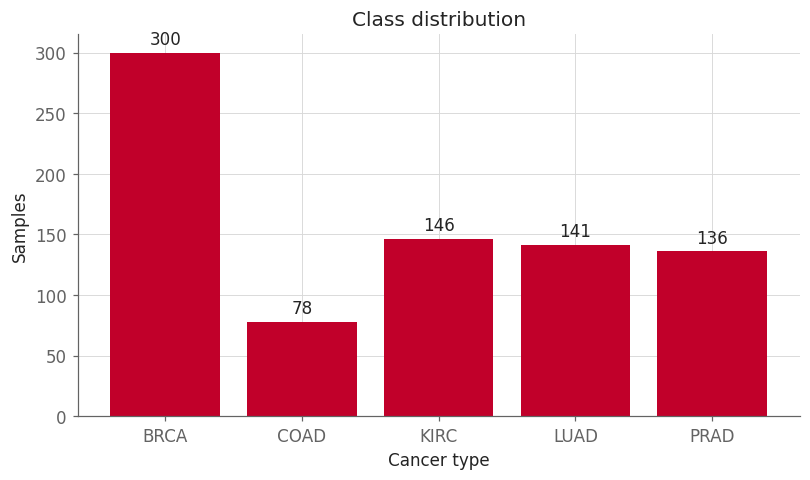

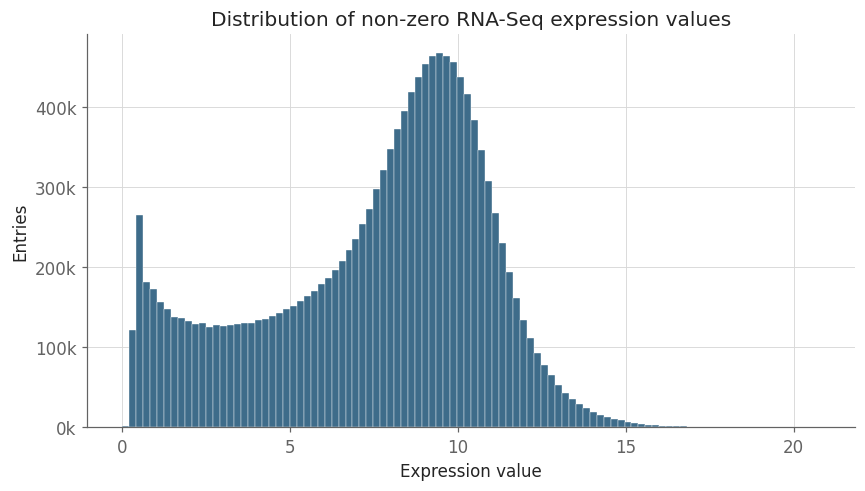


GENE VARIANCE QUANTILES
0.00     0.000000
0.25     0.343816
0.50     0.801383
0.75     2.173090
0.90     4.292749
0.99    13.019598
1.00    44.763847


,variance
0.000000,0.0000
0.250000,0.3438
0.500000,0.8014
0.750000,2.1731
0.900000,4.2927
0.990000,13.0196
1.000000,44.7638



Gespeicherte Dateien:
- /Users/richardmohling/Desktop/Uni/M.Sc. Quantive Decision Making in Economics and Management/5. Semester/Data Analytics/Data-Analytics/results_notebook_quick/dataset_summary.json
- /Users/richardmohling/Desktop/Uni/M.Sc. Quantive Decision Making in Economics and Management/5. Semester/Data Analytics/Data-Analytics/results_notebook_quick/class_distribution.csv
- /Users/richardmohling/Desktop/Uni/M.Sc. Quantive Decision Making in Economics and Management/5. Semester/Data Analytics/Data-Analytics/results_notebook_quick/class_distribution.png
- /Users/richardmohling/Desktop/Uni/M.Sc. Quantive Decision Making in Economics and Management/5. Semester/Data Analytics/Data-Analytics/results_notebook_quick/expression_value_distribution.png
- /Users/richardmohling/Desktop/Uni/M.Sc. Quantive Decision Making in Economics and Management/5. Semester/Data Analytics/Data-Analytics/results_notebook_quick/gene_variance_quantiles.csv


In [61]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display


def save_dataset_summary(
    X: pd.DataFrame,
    y: pd.Series,
    output_dir: Path,
) -> None:
    # Sicherstellen, dass der Ergebnisordner existiert
    output_dir.mkdir(parents=True, exist_ok=True)

    counts = y.value_counts().sort_index()
    gene_variance = X.var(axis=0)
    values = X.to_numpy()

    summary = {
        "samples": int(X.shape[0]),
        "genes": int(X.shape[1]),
        "nonconstant_genes": int((gene_variance > 0).sum()),
        "zero_variance_genes": int((gene_variance == 0).sum()),
        "all_zero_genes": int((X == 0).all(axis=0).sum()),
        "classes": int(y.nunique()),
        "missing_values": int(
            X.isna().sum().sum() + y.isna().sum()
        ),
        "minimum_expression": float(values.min()),
        "maximum_expression": float(values.max()),
        "share_exact_zero": float((values == 0).mean()),
        "class_counts": {
            cancer_type: int(count)
            for cancer_type, count in counts.items()
        },
    }

    # Zusammenfassung als JSON speichern
    summary_path = output_dir / "dataset_summary.json"
    summary_path.write_text(
        json.dumps(summary, indent=2),
        encoding="utf-8",
    )

    # Zusammenfassung im Notebook ausgeben
    print("=" * 50)
    print("DATASET SUMMARY")
    print("=" * 50)
    print(json.dumps(summary, indent=2, ensure_ascii=False))

    # Zusätzlich als übersichtliche Tabelle anzeigen
    summary_table = pd.DataFrame(
        {
            "Kennzahl": [
                "Tumorproben",
                "Gene",
                "Nicht-konstante Gene",
                "Gene ohne Varianz",
                "Vollständig leere Gene",
                "Krebsarten",
                "Fehlende Werte",
                "Minimale Expression",
                "Maximale Expression",
                "Anteil exakter Nullen",
            ],
            "Wert": [
                summary["samples"],
                summary["genes"],
                summary["nonconstant_genes"],
                summary["zero_variance_genes"],
                summary["all_zero_genes"],
                summary["classes"],
                summary["missing_values"],
                summary["minimum_expression"],
                summary["maximum_expression"],
                summary["share_exact_zero"],
            ],
        }
    )

    display(summary_table.style.hide(axis="index"))

    # Klassenverteilung speichern und anzeigen
    class_distribution = counts.rename("samples")
    class_distribution.to_csv(
        output_dir / "class_distribution.csv"
    )

    print("\n" + "=" * 50)
    print("CLASS DISTRIBUTION")
    print("=" * 50)
    print(class_distribution.to_string())

    display(
        class_distribution
        .rename_axis("Cancer type")
        .to_frame()
        .style
    )

    fig, ax = plt.subplots(figsize=(7.5, 4.5))

    bars = ax.bar(
        counts.index,
        counts.values,
        color=JGU_RED,
    )

    ax.bar_label(bars, padding=3)

    ax.set(
        title="Class distribution",
        xlabel="Cancer type",
        ylabel="Samples",
    )

    ax.spines[["top", "right"]].set_visible(False)

    fig.tight_layout()
    fig.savefig(
        output_dir / "class_distribution.png",
        dpi=180,
    )

    # Garantiert die Anzeige im Notebook
    display(fig)
    plt.close(fig)

    # Verteilung der positiven Expressionswerte
    nonzero = values[values > 0]

    fig, ax = plt.subplots(figsize=(8, 4.6))

    ax.hist(
        nonzero,
        bins=100,
        color=BLUE,
        edgecolor="white",
        linewidth=0.25,
    )

    ax.set(
        title="Distribution of non-zero RNA-Seq expression values",
        xlabel="Expression value",
        ylabel="Entries",
    )

    ax.yaxis.set_major_formatter(
        plt.FuncFormatter(
            lambda value, _: f"{value / 1_000:.0f}k"
        )
    )

    fig.tight_layout()
    fig.savefig(
        output_dir / "expression_value_distribution.png",
        dpi=180,
    )

    # Garantiert die Anzeige im Notebook
    display(fig)
    plt.close(fig)

    # Varianzquantile berechnen und speichern
    variance_summary = gene_variance.quantile(
        [0, 0.25, 0.5, 0.75, 0.9, 0.99, 1]
    ).rename("variance")

    variance_summary.to_csv(
        output_dir / "gene_variance_quantiles.csv"
    )

    print("\n" + "=" * 50)
    print("GENE VARIANCE QUANTILES")
    print("=" * 50)
    print(variance_summary.to_string())

    display(variance_summary.to_frame().style.format("{:,.4f}"))

    print("\nGespeicherte Dateien:")
    print(f"- {summary_path}")
    print(f"- {output_dir / 'class_distribution.csv'}")
    print(f"- {output_dir / 'class_distribution.png'}")
    print(f"- {output_dir / 'expression_value_distribution.png'}")
    print(f"- {output_dir / 'gene_variance_quantiles.csv'}")


# ---------------------------------------------------------
# Funktion unmittelbar ausführen
# ---------------------------------------------------------

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Falls X und y noch nicht geladen wurden, diese Zeile aktivieren:
# X, y = load_data(DATA_DIR)

save_dataset_summary(
    X=X,
    y=y,
    output_dir=OUTPUT_DIR,
)

## 2. Explorative Datenanalyse

Die PCA visualisiert die dominante Struktur der Expressionsdaten. Ergänzend
zeigen Varianzdiagnostik und ein flacher einzelner Entscheidungsbaum, welche
Eigenschaften die spätere Ensemble-Analyse motivieren.


In [62]:
def create_pca_plot(
    X: pd.DataFrame, y: pd.Series, output_dir: Path, random_state: int
) -> None:
    # The UCI values are already normalized expression measurements. The primary
    # PCA is therefore centred but not standardized gene by gene; standardizing
    # would give near-constant genes the same weight as high-variance genes.
    variance = X.var(axis=0)
    X_nonconstant = X.loc[:, variance > 0]
    pca = PCA(n_components=4, svd_solver="randomized", random_state=random_state)
    scores = pca.fit_transform(X_nonconstant)

    fig, ax = plt.subplots(figsize=(8, 6))
    for label in CLASS_ORDER:
        mask = y.to_numpy() == label
        ax.scatter(
            scores[mask, 0],
            scores[mask, 1],
            s=28,
            alpha=0.85,
            label=f"{label} (n={mask.sum()})",
            color=CLASS_COLORS[label],
            marker=CLASS_MARKERS[label],
            edgecolor="white",
            linewidth=0.4,
        )
    ax.set(
        title="PCA of RNA-Seq expression profiles",
        xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)",
        ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)",
    )
    ax.legend(title="Cancer type")
    ax.grid(alpha=0.18)
    fig.tight_layout()
    fig.savefig(output_dir / "pca_cancer_types.png", dpi=180)
    plt.close(fig)

    pd.DataFrame(
        {
            "sample": X.index,
            "Class": y.to_numpy(),
            "PC1": scores[:, 0],
            "PC2": scores[:, 1],
            "PC3": scores[:, 2],
            "PC4": scores[:, 3],
        }
    ).to_csv(output_dir / "pca_scores.csv", index=False)

    fig, ax = plt.subplots(figsize=(8, 6))
    for label in CLASS_ORDER:
        mask = y.to_numpy() == label
        ax.scatter(
            scores[mask, 2],
            scores[mask, 3],
            s=28,
            alpha=0.85,
            label=f"{label} (n={mask.sum()})",
            color=CLASS_COLORS[label],
            marker=CLASS_MARKERS[label],
            edgecolor="white",
            linewidth=0.4,
        )
    ax.set(
        title="PCA of RNA-Seq expression profiles: PC3 and PC4",
        xlabel=f"PC3 ({pca.explained_variance_ratio_[2]:.1%} variance)",
        ylabel=f"PC4 ({pca.explained_variance_ratio_[3]:.1%} variance)",
    )
    ax.legend(title="Cancer type")
    ax.grid(alpha=0.18)
    fig.tight_layout()
    fig.savefig(output_dir / "pca_cancer_types_pc3_pc4.png")
    plt.close(fig)

    # Sensitivity plot: the previous group code standardized every gene. Keeping
    # it as a separate diagnostic makes the preprocessing choice transparent.
    X_standardized = StandardScaler().fit_transform(X_nonconstant)
    pca_scaled = PCA(
        n_components=2, svd_solver="randomized", random_state=random_state
    )
    scaled_scores = pca_scaled.fit_transform(X_standardized)
    fig, ax = plt.subplots(figsize=(8, 6))
    for label in CLASS_ORDER:
        mask = y.to_numpy() == label
        ax.scatter(
            scaled_scores[mask, 0],
            scaled_scores[mask, 1],
            s=24,
            alpha=0.75,
            label=label,
            color=CLASS_COLORS[label],
            marker=CLASS_MARKERS[label],
        )
    ax.set(
        title="Sensitivity: PCA after gene-wise standardization",
        xlabel=f"PC1 ({pca_scaled.explained_variance_ratio_[0]:.1%} variance)",
        ylabel=f"PC2 ({pca_scaled.explained_variance_ratio_[1]:.1%} variance)",
    )
    ax.legend(title="Cancer type")
    ax.grid(alpha=0.18)
    fig.tight_layout()
    fig.savefig(output_dir / "pca_cancer_types_standardized.png")
    plt.close(fig)

    pca_metadata = {
        "primary_preprocessing": "centred, not gene-wise standardized",
        "primary_explained_variance_ratio": pca.explained_variance_ratio_.tolist(),
        "standardized_explained_variance_ratio": (
            pca_scaled.explained_variance_ratio_.tolist()
        ),
    }
    (output_dir / "pca_metadata.json").write_text(
        json.dumps(pca_metadata, indent=2), encoding="utf-8"
    )


In [63]:
def create_variance_diagnostics(
    X: pd.DataFrame, output_dir: Path, random_state: int
) -> None:
    variance = X.var(axis=0)
    positive = variance[variance > 0].sort_values(ascending=False)
    top = positive.head(100)
    cumulative_share = top.cumsum() / positive.sum() * 100

    fig, (ax_top, ax_bottom) = plt.subplots(
        2,
        1,
        figsize=(8, 6.2),
        sharex=True,
        gridspec_kw={"height_ratios": [1, 1.15], "hspace": 0.16},
    )
    ranks = np.arange(1, len(top) + 1)
    ax_top.bar(ranks, top / positive.sum() * 100, color=BLUE, width=0.8)
    ax_top.set(
        title="Variance concentration in the 100 most variable genes",
        ylabel="Share per gene (%)",
    )
    ax_bottom.plot(ranks, cumulative_share, color=JGU_RED, linewidth=2)
    ax_bottom.set(xlabel="Gene rank by variance", ylabel="Cumulative share (%)")
    for k in (10, 50, 100):
        ax_bottom.scatter(k, cumulative_share.iloc[k - 1], color=JGU_RED, zorder=3)
        ax_bottom.annotate(
            f"top {k}: {cumulative_share.iloc[k - 1]:.1f}%",
            (k, cumulative_share.iloc[k - 1]),
            xytext=(0, 8),
            textcoords="offset points",
            ha="center" if k < 100 else "right",
            fontsize=9,
        )
    fig.savefig(output_dir / "top_variance_genes.png")
    plt.close(fig)

    X_nonconstant = X.loc[:, variance > 0]
    n_components = min(100, X_nonconstant.shape[0] - 1)
    pca = PCA(
        n_components=n_components,
        svd_solver="randomized",
        random_state=random_state,
    ).fit(X_nonconstant)
    explained = pca.explained_variance_ratio_ * 100
    cumulative = np.cumsum(explained)
    pcs = np.arange(1, n_components + 1)
    fig, (ax_top, ax_bottom) = plt.subplots(
        2, 1, figsize=(8, 6.3), gridspec_kw={"hspace": 0.4}
    )
    ax_top.bar(pcs[:30], explained[:30], color=BLUE)
    ax_top.set(
        title="Scree plot of the first 30 principal components",
        xlabel="Principal component",
        ylabel="Variance explained (%)",
    )
    ax_bottom.plot(pcs, cumulative, color=JGU_RED, linewidth=2)
    ax_bottom.set(
        title="Cumulative variance explained",
        xlabel="Number of principal components",
        ylabel="Cumulative (%)",
    )
    fig.savefig(output_dir / "pca_scree_plot.png")
    plt.close(fig)


In [64]:
def create_tree_plot(
    X: pd.DataFrame,
    y: pd.Series,
    output_dir: Path,
    random_state: int,
) -> DecisionTreeClassifier:
    """Fit, print, save, and display the exact illustrative decision tree."""
    from IPython.display import display

    output_dir.mkdir(parents=True, exist_ok=True)

    # Remove constant genes before supervised feature selection.
    variance = VarianceThreshold()
    X_var = variance.fit_transform(X)
    var_genes = X.columns.to_numpy()[variance.get_support()]

    # Give the tree the 50 strongest ANOVA-ranked genes as candidates.
    k = min(50, X_var.shape[1])
    selector = SelectKBest(score_func=f_classif, k=k)
    X_selected = selector.fit_transform(X_var, y)
    selected_genes = var_genes[selector.get_support()]

    # This is the one and only illustrative tree fitted by this function.
    tree = DecisionTreeClassifier(
        criterion="gini",
        max_depth=4,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=random_state,
    )
    tree.fit(X_selected, y)

    # Identify the genes that the fitted tree actually uses for splits.
    split_feature_indices = tree.tree_.feature[
        tree.tree_.feature >= 0
    ]
    used_feature_indices = np.unique(split_feature_indices)
    used_genes = selected_genes[used_feature_indices]
    split_count = int((tree.tree_.feature >= 0).sum())
    training_accuracy = float(tree.score(X_selected, y))

    print("=" * 60)
    print("EXACT ILLUSTRATIVE DECISION TREE")
    print("=" * 60)
    print(f"Genes before variance filter: {X.shape[1]}")
    print(f"Genes after variance filter:  {X_var.shape[1]}")
    print(f"Candidate genes after ANOVA: {X_selected.shape[1]}")
    print(f"Tree depth:                 {tree.get_depth()}")
    print(f"Split nodes:                {split_count}")
    print(f"Leaf nodes:                 {tree.get_n_leaves()}")
    print(f"Distinct genes used:        {len(used_genes)}")
    print(f"Descriptive training accuracy: {training_accuracy:.4f}")
    print("\nGenes actually used by the tree:")
    for gene in used_genes:
        print(f"- {gene}")

    # Render exactly the fitted tree. No second simplified tree is fitted.
    fig, ax = plt.subplots(figsize=(32, 16), facecolor="white")
    plot_tree(
        tree,
        feature_names=selected_genes.tolist(),
        class_names=tree.classes_.tolist(),
        filled=True,
        rounded=True,
        impurity=True,
        proportion=False,
        precision=3,
        fontsize=9,
        ax=ax,
    )
    ax.set_title(
        "Exact depth-4 decision tree on the ANOVA-selected 50-gene panel "
        f"(descriptive training accuracy = {training_accuracy:.3f})",
        fontsize=18,
        pad=18,
    )
    fig.tight_layout()

    png_path = output_dir / "decision_tree_depth4_exact.png"
    pdf_path = output_dir / "decision_tree_depth4_exact.pdf"
    fig.savefig(
        png_path,
        dpi=300,
        bbox_inches="tight",
        pad_inches=0.15,
        facecolor="white",
    )
    fig.savefig(
        pdf_path,
        bbox_inches="tight",
        pad_inches=0.15,
        facecolor="white",
    )

    # Display the same fitted tree directly in the notebook.
    display(fig)
    plt.close(fig)

    print("\nSaved exact tree:")
    print(f"- {png_path}")
    print(f"- {pdf_path}")

    return tree


## 3. Leakage-sichere Modell-Pipelines

Alle datenabhängigen Schritte – Varianzfilter, Skalierung und Feature Selection –
werden innerhalb des jeweiligen Trainingsfolds angepasst. Der Testfold beeinflusst
die Auswahl der Gene daher nicht.


In [65]:
def build_rf_pipeline(k: int, cfg: RunConfig) -> Pipeline:
    selector_model = RandomForestClassifier(
        n_estimators=cfg.rf_selector_trees,
        max_features="sqrt",
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=cfg.random_state,
    )
    final_model = RandomForestClassifier(
        n_estimators=cfg.rf_model_trees,
        max_features="sqrt",
        min_samples_leaf=1,
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=cfg.random_state + 1,
    )
    return Pipeline(
        [
            ("variance", VarianceThreshold()),
            (
                "selector",
                SelectFromModel(
                    selector_model,
                    threshold=-np.inf,
                    max_features=k,
                ),
            ),
            ("model", final_model),
        ]
    )


In [66]:
def build_l1_pipeline(k: int, cfg: RunConfig) -> Pipeline:
    selector_model = LogisticRegression(
        penalty="l1",
        # liblinear's one-vs-rest L1 fits are substantially faster than SAGA
        # for this p >> n dataset while still providing sparse coefficients.
        solver="liblinear",
        C=0.1,
        class_weight="balanced",
        max_iter=1500 if cfg.mode == "full" else 400,
        tol=1e-3,
        random_state=cfg.random_state,
    )
    final_model = LogisticRegression(
        penalty="l2",
        solver="lbfgs",
        C=1.0,
        class_weight="balanced",
        max_iter=1500,
        random_state=cfg.random_state + 1,
    )
    return Pipeline(
        [
            ("variance", VarianceThreshold()),
            ("scale", StandardScaler()),
            (
                "selector",
                SelectFromModel(
                    selector_model,
                    threshold=-np.inf,
                    max_features=k,
                    norm_order=1,
                ),
            ),
            ("model", final_model),
        ]
    )


In [67]:
# def build_anova_rf_pipeline(k: int, cfg: RunConfig) -> Pipeline:
#     """Univariate ANOVA ranking followed by the same final random forest."""
#     final_model = RandomForestClassifier(
#         n_estimators=cfg.rf_model_trees,
#         max_features="sqrt",
#         min_samples_leaf=1,
#         class_weight="balanced_subsample",
#         n_jobs=-1,
#         random_state=cfg.random_state + 1,
#     )
#     return Pipeline(
#         [
#             ("variance", VarianceThreshold()),
#             ("selector", SelectKBest(score_func=f_classif, k=k)),
#             ("model", final_model),
#         ]
#     )


In [68]:
def selected_gene_names(pipe: Pipeline, all_genes: pd.Index) -> np.ndarray:
    variance_mask = pipe.named_steps["variance"].get_support()
    genes_after_variance = all_genes.to_numpy()[variance_mask]
    selector_mask = pipe.named_steps["selector"].get_support()
    return genes_after_variance[selector_mask]


In [69]:
def fold_metrics(
    y_true: pd.Series,
    y_pred: np.ndarray,
    probabilities: np.ndarray,
    class_order: np.ndarray,
) -> dict[str, float]:
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
        "macro_roc_auc_ovr": roc_auc_score(
            y_true,
            probabilities,
            labels=class_order,
            multi_class="ovr",
            average="macro",
        ),
    }


## 4. Kreuzvalidierung und Benchmarks

Die Modelle werden auf identischen stratified Folds verglichen. Neben der
Vorhersagegüte erfassen wir die Auswahlstabilität der Gene und berechnen die
Permutation Importance ausschließlich auf held-out Beobachtungen.


In [70]:
def evaluate_models(
    X: pd.DataFrame,
    y: pd.Series,
    output_dir: Path,
    cfg: RunConfig,
) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    cv = StratifiedKFold(
        n_splits=cfg.folds, shuffle=True, random_state=cfg.random_state
    )
    splits = list(cv.split(X, y))
    builders = {
        "Random forest": build_rf_pipeline,
        "ANOVA + random forest": build_anova_rf_pipeline,
        "L1 logistic": build_l1_pipeline,
    }

    metric_rows: list[dict[str, object]] = []
    selection_rows: list[dict[str, object]] = []
    importance_rows: list[dict[str, object]] = []
    oof_rows: list[dict[str, object]] = []

    for model_name, builder in builders.items():
        for k in cfg.gene_counts:
            print(f"[{model_name}] evaluating k={k}", flush=True)
            for fold, (train_idx, test_idx) in enumerate(splits, start=1):
                X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
                y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
                pipe = builder(k, cfg)
                pipe.fit(X_train, y_train)

                y_pred = pipe.predict(X_test)
                probabilities = pipe.predict_proba(X_test)
                class_order = pipe.named_steps["model"].classes_
                metrics = fold_metrics(
                    y_test, y_pred, probabilities, class_order
                )
                metric_rows.append(
                    {
                        "model": model_name,
                        "genes": k,
                        "fold": fold,
                        **metrics,
                    }
                )

                genes = selected_gene_names(pipe, X.columns)
                for gene in genes:
                    selection_rows.append(
                        {
                            "model": model_name,
                            "genes_in_model": k,
                            "fold": fold,
                            "gene": gene,
                        }
                    )

                if k == cfg.importance_gene_count:
                    for sample, truth, pred in zip(
                        X_test.index, y_test.to_numpy(), y_pred
                    ):
                        oof_rows.append(
                            {
                                "model": model_name,
                                "sample": sample,
                                "truth": truth,
                                "prediction": pred,
                            }
                        )

                    if model_name == "Random forest":
                        # Permute only the selected held-out features. The ranking
                        # and final classifier were both learned without this fold.
                        X_test_selected = pipe[:-1].transform(X_test)
                        importance_specs = (
                            ("macro_f1", "f1_macro", cfg.permutation_repeats),
                            (
                                "log_loss",
                                "neg_log_loss",
                                cfg.logloss_permutation_repeats,
                            ),
                        )
                        for metric, scoring, repeats in importance_specs:
                            perm = permutation_importance(
                                pipe.named_steps["model"],
                                X_test_selected,
                                y_test,
                                scoring=scoring,
                                n_repeats=repeats,
                                random_state=cfg.random_state + fold,
                                n_jobs=1,
                            )
                            for gene, mean, std in zip(
                                genes,
                                perm.importances_mean,
                                perm.importances_std,
                            ):
                                importance_rows.append(
                                    {
                                        "metric": metric,
                                        "fold": fold,
                                        "gene": gene,
                                        "importance_mean": float(mean),
                                        "importance_std": float(std),
                                    }
                                )

    metrics_df = pd.DataFrame(metric_rows)
    selections_df = pd.DataFrame(selection_rows)
    importance_df = pd.DataFrame(importance_rows)
    metrics_df.to_csv(output_dir / "cv_fold_metrics.csv", index=False)
    selections_df.to_csv(output_dir / "selected_genes_by_fold.csv", index=False)
    importance_df.to_csv(
        output_dir / "rf_permutation_importance_by_fold.csv", index=False
    )
    pd.DataFrame(oof_rows).to_csv(
        output_dir / "oof_predictions_k50.csv", index=False
    )
    return metrics_df, selections_df, importance_df


In [71]:
def evaluate_all_gene_random_forest(
    X: pd.DataFrame,
    y: pd.Series,
    output_dir: Path,
    cfg: RunConfig,
) -> pd.DataFrame:
    """All-gene baseline with OOB scores and fold-wise impurity stability."""
    cv = StratifiedKFold(
        n_splits=cfg.folds, shuffle=True, random_state=cfg.random_state
    )
    metric_rows: list[dict[str, object]] = []
    oof_rows: list[dict[str, object]] = []
    impurity_folds: dict[str, pd.Series] = {}

    print("[All-gene random forest] evaluating baseline", flush=True)
    for fold, (train_idx, test_idx) in enumerate(cv.split(X, y), start=1):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
        variance = VarianceThreshold()
        X_train_var = variance.fit_transform(X_train)
        X_test_var = variance.transform(X_test)
        genes = X.columns.to_numpy()[variance.get_support()]
        model = RandomForestClassifier(
            n_estimators=cfg.rf_model_trees,
            max_features="sqrt",
            class_weight="balanced_subsample",
            oob_score=True,
            n_jobs=-1,
            random_state=cfg.random_state + fold,
        )
        model.fit(X_train_var, y_train)
        prediction = model.predict(X_test_var)
        probabilities = model.predict_proba(X_test_var)
        metrics = fold_metrics(
            y_test, prediction, probabilities, model.classes_
        )
        metric_rows.append(
            {
                "model": "All-gene random forest",
                "genes": len(genes),
                "fold": fold,
                "oob_accuracy": float(model.oob_score_),
                **metrics,
            }
        )
        impurity_folds[f"fold_{fold}"] = pd.Series(
            model.feature_importances_, index=genes
        )
        for sample, truth, pred in zip(
            X_test.index, y_test.to_numpy(), prediction
        ):
            oof_rows.append(
                {
                    "sample": sample,
                    "truth": truth,
                    "prediction": pred,
                }
            )

    metrics_df = pd.DataFrame(metric_rows)
    metrics_df.to_csv(output_dir / "all_gene_rf_fold_metrics.csv", index=False)
    oof_df = pd.DataFrame(oof_rows)
    oof_df.to_csv(output_dir / "all_gene_rf_oof_predictions.csv", index=False)

    impurity_df = pd.DataFrame(impurity_folds).fillna(0.0)
    impurity_df["mean"] = impurity_df.mean(axis=1)
    impurity_df["std"] = impurity_df.drop(columns="mean").std(axis=1)
    impurity_df = impurity_df.sort_values("mean", ascending=False)
    impurity_df.to_csv(
        output_dir / "all_gene_rf_impurity_importance.csv"
    )

    top = impurity_df.head(20).sort_values("mean")
    fig, ax = plt.subplots(figsize=(8, 6.4))
    ax.barh(top.index, top["mean"] * 100, color=BLUE)
    ax.errorbar(
        top["mean"] * 100,
        top.index,
        xerr=top["std"] * 100,
        fmt="none",
        ecolor=INK,
        linewidth=1,
    )
    ax.set(
        title="All-gene random forest: impurity importance stability",
        xlabel="Mean decrease in impurity (% of total, mean +/- SD)",
        ylabel="Gene",
    )
    fig.tight_layout()
    fig.savefig(output_dir / "all_gene_rf_impurity_importance.png")
    plt.close(fig)

    labels = CLASS_ORDER
    fig, ax = plt.subplots(figsize=(6, 5.5))
    ConfusionMatrixDisplay.from_predictions(
        oof_df["truth"],
        oof_df["prediction"],
        labels=labels,
        display_labels=labels,
        cmap="Blues",
        values_format="d",
        ax=ax,
        colorbar=False,
    )
    errors = int((oof_df["truth"] != oof_df["prediction"]).sum())
    ax.set_title(
        f"All-gene random forest: {errors} of {len(oof_df)} misclassified"
    )
    fig.tight_layout()
    fig.savefig(output_dir / "all_gene_rf_confusion_matrix.png")
    plt.close(fig)
    return metrics_df


## 5. Ergebnisse zusammenfassen und visualisieren


In [72]:
def summarize_and_plot_results(
    metrics: pd.DataFrame,
    selections: pd.DataFrame,
    importances: pd.DataFrame,
    output_dir: Path,
    cfg: RunConfig,
) -> None:
    metric_names = [
        "accuracy",
        "balanced_accuracy",
        "macro_f1",
        "macro_roc_auc_ovr",
    ]
    summary = (
        metrics.groupby(["model", "genes"])[metric_names]
        .agg(["mean", "std"])
        .reset_index()
    )
    summary.columns = [
        "_".join(str(part) for part in col if part).rstrip("_")
        if isinstance(col, tuple)
        else col
        for col in summary.columns
    ]
    summary.to_csv(output_dir / "cv_summary.csv", index=False)

    fig, ax = plt.subplots(figsize=(8, 5))
    model_colors = {
        "Random forest": JGU_RED,
        "ANOVA + random forest": BLUE,
        "L1 logistic": "#7A7A7A",
    }
    for model_name, group in summary.groupby("model"):
        group = group.sort_values("genes")
        ax.errorbar(
            group["genes"],
            group["macro_f1_mean"],
            yerr=group["macro_f1_std"],
            marker="o",
            capsize=3,
            linewidth=2,
            label=model_name,
            color=model_colors.get(model_name),
        )
    ax.set_xscale("log")
    ax.set(
        title="Cancer-type classification versus number of selected genes",
        xlabel="Selected genes (log scale)",
        ylabel="Macro-F1 (cross-validation mean +/- SD)",
        ylim=(0.25, 1.03),
    )
    ax.grid(alpha=0.2)
    ax.legend(frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
    fig.savefig(output_dir / "performance_vs_gene_count.png", dpi=180)
    plt.close(fig)

    central = selections[
        selections["genes_in_model"] == cfg.importance_gene_count
    ]
    stability = (
        central.groupby(["model", "gene"])
        .size()
        .rename("selected_folds")
        .reset_index()
    )
    stability["selection_frequency"] = stability["selected_folds"] / cfg.folds
    stability = stability.sort_values(
        ["model", "selected_folds", "gene"], ascending=[True, False, True]
    )
    stability.to_csv(output_dir / "gene_selection_stability_k50.csv", index=False)

    threshold = int(np.ceil(cfg.folds / 2))
    stable_rf = set(
        stability.loc[
            (stability["model"] == "Random forest")
            & (stability["selected_folds"] >= threshold),
            "gene",
        ]
    )
    stable_l1 = set(
        stability.loc[
            (stability["model"] == "L1 logistic")
            & (stability["selected_folds"] >= threshold),
            "gene",
        ]
    )
    stable_anova = set(
        stability.loc[
            (stability["model"] == "ANOVA + random forest")
            & (stability["selected_folds"] >= threshold),
            "gene",
        ]
    )
    overlap = pd.DataFrame(
        {
            "gene": sorted(stable_rf | stable_l1),
        }
    )
    overlap["stable_random_forest"] = overlap["gene"].isin(stable_rf)
    overlap["stable_l1_logistic"] = overlap["gene"].isin(stable_l1)
    overlap["selected_by_both"] = (
        overlap["stable_random_forest"] & overlap["stable_l1_logistic"]
    )
    overlap.to_csv(output_dir / "stable_gene_overlap_k50.csv", index=False)

    all_genes = sorted(stable_rf | stable_l1 | stable_anova)
    overlap_all = pd.DataFrame({"gene": all_genes})
    overlap_all["stable_random_forest"] = overlap_all["gene"].isin(stable_rf)
    overlap_all["stable_anova_forest"] = overlap_all["gene"].isin(stable_anova)
    overlap_all["stable_l1_logistic"] = overlap_all["gene"].isin(stable_l1)
    overlap_all["selected_by_all_three"] = (
        overlap_all["stable_random_forest"]
        & overlap_all["stable_anova_forest"]
        & overlap_all["stable_l1_logistic"]
    )
    overlap_all.to_csv(
        output_dir / "stable_gene_overlap_all_selectors_k50.csv", index=False
    )

    if not importances.empty:
        perm_summary = (
            importances.groupby(["metric", "gene"])["importance_mean"]
            .agg(["mean", "std", "count"])
            .reset_index()
        )
        rf_stability = stability.loc[
            stability["model"] == "Random forest",
            ["gene", "selected_folds", "selection_frequency"],
        ]
        perm_summary = perm_summary.merge(rf_stability, on="gene", how="left")
        perm_summary = perm_summary.sort_values(
            ["metric", "selected_folds", "mean"],
            ascending=[True, False, False],
        )
        perm_summary.to_csv(
            output_dir / "rf_permutation_importance_summary.csv", index=False
        )
        for metric, x_label, filename in (
            (
                "macro_f1",
                "Decrease in held-out Macro-F1 after permutation",
                "rf_top_permutation_importance.png",
            ),
            (
                "log_loss",
                "Increase in held-out log loss after permutation",
                "rf_top_permutation_importance_log_loss.png",
            ),
        ):
            top = (
                perm_summary.loc[
                    (perm_summary["metric"] == metric)
                    & (perm_summary["selected_folds"] >= threshold)
                    & (perm_summary["mean"] > 0)
                ]
                .sort_values("mean", ascending=False)
                .head(20)
                .sort_values("mean")
                .copy()
            )
            top["std"] = top["std"].fillna(0.0)
            fig, ax = plt.subplots(figsize=(8, 6.5))
            ax.barh(top["gene"], top["mean"], xerr=top["std"], color=JGU_RED)
            ax.set(
                title=(
                    "Random forest held-out permutation importance "
                    f"(stable genes, k={cfg.importance_gene_count})"
                ),
                xlabel=x_label,
                ylabel="Gene",
            )
            fig.tight_layout()
            fig.savefig(output_dir / filename)
            plt.close(fig)

    oof_path = output_dir / "oof_predictions_k50.csv"
    if oof_path.exists():
        oof = pd.read_csv(oof_path)
        labels = sorted(set(oof["truth"]) | set(oof["prediction"]))
        for model_name, group in oof.groupby("model"):
            fig, ax = plt.subplots(figsize=(6, 5.5))
            ConfusionMatrixDisplay.from_predictions(
                group["truth"],
                group["prediction"],
                labels=labels,
                display_labels=labels,
                normalize="true",
                cmap="Blues",
                values_format=".2f",
                ax=ax,
                colorbar=False,
            )
            ax.set_title(
                f"{model_name}: out-of-fold confusion matrix "
                f"(k={cfg.importance_gene_count})"
            )
            fig.tight_layout()
            safe_name = model_name.lower().replace(" ", "_")
            fig.savefig(
                output_dir / f"confusion_matrix_{safe_name}_k50.png", dpi=180
            )
            plt.close(fig)


In [73]:
def write_run_notes(output_dir: Path, cfg: RunConfig) -> None:
    note = f"""# Run notes

- Mode: `{cfg.mode}`
- Cross-validation: {cfg.folds}-fold stratified CV
- Gene counts: {', '.join(map(str, cfg.gene_counts))}
- Random-forest selector trees: {cfg.rf_selector_trees}
- Final random-forest trees: {cfg.rf_model_trees}
- Macro-F1 permutation repetitions: {cfg.permutation_repeats}
- Log-loss permutation repetitions: {cfg.logloss_permutation_repeats}
- Random seed: {cfg.random_state}

## Combined model comparison

- Random-forest feature selection followed by a random forest
- ANOVA F-statistic selection followed by the same random forest
- L1-logistic feature selection followed by L2-logistic classification
- All-gene random-forest baseline with OOB accuracy and fold-wise impurity stability

## Interpretation warning

The performance-versus-gene-count curve compares pre-specified gene counts using
the same outer folds.  Selecting the visually best gene count and quoting that same
score as a final unbiased estimate would be optimistic.  For a publication-grade
final estimate, lock the chosen configuration and evaluate it on a separate external
cohort or add a fully nested outer evaluation.

Feature selection is fitted separately inside every training fold. The held-out fold
is used only for evaluation and permutation importance. Macro-F1 permutation
importance remains easy to interpret; log-loss permutation importance is the more
sensitive diagnostic when accuracy is nearly saturated.
"""
    (output_dir / "RUN_NOTES.md").write_text(note, encoding="utf-8")


## 6. Analyse ausführen

Die folgende Zelle legt Modus, Daten- und Ergebnisordner fest. `quick` dient als
technischer Funktionstest; `full` reproduziert die finalen Einstellungen mit
Seed 555 und fünf Cross-Validation-Folds.


In [74]:
MODE = "quick"  # Auf "full" setzen, um die finalen Ergebnisse zu reproduzieren.
DATA_DIR = DEFAULT_DATA_DIR
OUTPUT_DIR = PROJECT_DIR / f"results_notebook_{MODE}"

cfg = make_config(MODE)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str((OUTPUT_DIR / ".mplconfig").resolve()))

print(f"Modus: {cfg.mode}")
print(f"Seed: {cfg.random_state}")
print(f"Daten: {DATA_DIR.resolve()}")
print(f"Ergebnisse: {OUTPUT_DIR.resolve()}")


Modus: quick
Seed: 555
Daten: /Users/richardmohling/Desktop/Uni/M.Sc. Quantive Decision Making in Economics and Management/5. Semester/Data Analytics/Data-Analytics/data/pancan
Ergebnisse: /Users/richardmohling/Desktop/Uni/M.Sc. Quantive Decision Making in Economics and Management/5. Semester/Data Analytics/Data-Analytics/results_notebook_quick


### 6.1 Daten einlesen und beschreiben


Geladen: 801 Samples, 20531 Gene, Klassen={'PRAD': 136, 'LUAD': 141, 'BRCA': 300, 'KIRC': 146, 'COAD': 78}
DATASET SUMMARY
{
  "samples": 801,
  "genes": 20531,
  "nonconstant_genes": 20264,
  "zero_variance_genes": 267,
  "all_zero_genes": 267,
  "classes": 5,
  "missing_values": 0,
  "minimum_expression": 0.0,
  "maximum_expression": 20.77882957458496,
  "share_exact_zero": 0.1421755512248431,
  "class_counts": {
    "BRCA": 300,
    "COAD": 78,
    "KIRC": 146,
    "LUAD": 141,
    "PRAD": 136
  }
}


Kennzahl,Wert
Tumorproben,801.000000
Gene,20531.000000
Nicht-konstante Gene,20264.000000
Gene ohne Varianz,267.000000
Vollständig leere Gene,267.000000
Krebsarten,5.000000
Fehlende Werte,0.000000
Minimale Expression,0.000000
Maximale Expression,20.778830
Anteil exakter Nullen,0.142176



CLASS DISTRIBUTION
Class
BRCA    300
COAD     78
KIRC    146
LUAD    141
PRAD    136


,samples
Cancer type,
BRCA,300
COAD,78
KIRC,146
LUAD,141
PRAD,136


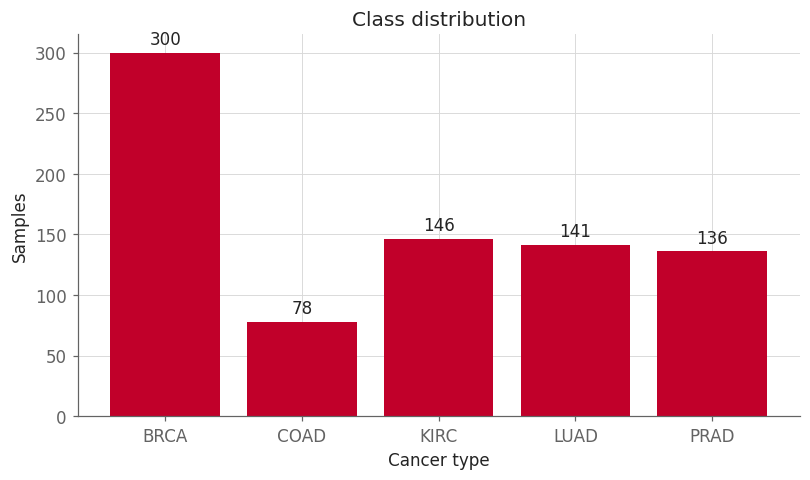

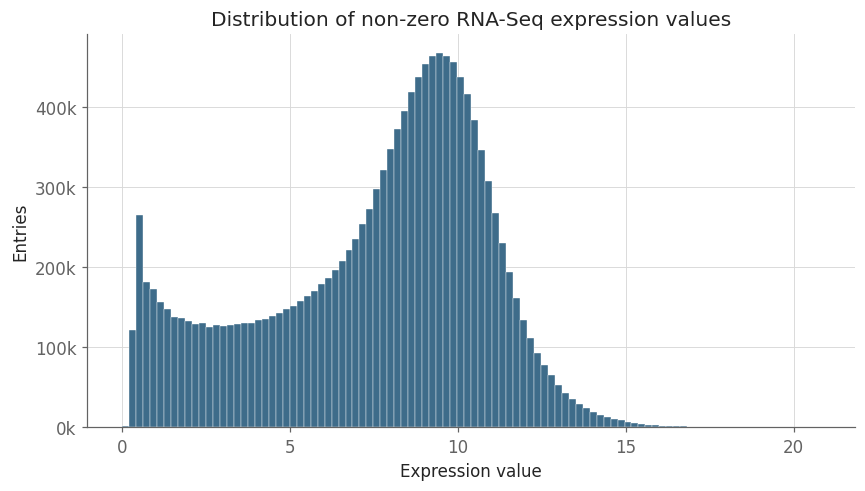


GENE VARIANCE QUANTILES
0.00     0.000000
0.25     0.343816
0.50     0.801383
0.75     2.173090
0.90     4.292749
0.99    13.019598
1.00    44.763847


,variance
0.000000,0.0000
0.250000,0.3438
0.500000,0.8014
0.750000,2.1731
0.900000,4.2927
0.990000,13.0196
1.000000,44.7638



Gespeicherte Dateien:
- /Users/richardmohling/Desktop/Uni/M.Sc. Quantive Decision Making in Economics and Management/5. Semester/Data Analytics/Data-Analytics/results_notebook_quick/dataset_summary.json
- /Users/richardmohling/Desktop/Uni/M.Sc. Quantive Decision Making in Economics and Management/5. Semester/Data Analytics/Data-Analytics/results_notebook_quick/class_distribution.csv
- /Users/richardmohling/Desktop/Uni/M.Sc. Quantive Decision Making in Economics and Management/5. Semester/Data Analytics/Data-Analytics/results_notebook_quick/class_distribution.png
- /Users/richardmohling/Desktop/Uni/M.Sc. Quantive Decision Making in Economics and Management/5. Semester/Data Analytics/Data-Analytics/results_notebook_quick/expression_value_distribution.png
- /Users/richardmohling/Desktop/Uni/M.Sc. Quantive Decision Making in Economics and Management/5. Semester/Data Analytics/Data-Analytics/results_notebook_quick/gene_variance_quantiles.csv


### Datensatzübersicht

Kennzahl,Wert
Tumorproben,801
Genmerkmale,20531
Krebsarten,5


### Klassenverteilung

,Anzahl
Krebsart,
BRCA,300
KIRC,146
LUAD,141
PRAD,136
COAD,78


In [75]:
X, y = load_data(DATA_DIR)
print(
    f"Geladen: {X.shape[0]} Samples, {X.shape[1]} Gene, "
    f"Klassen={dict(Counter(y))}"
)

(OUTPUT_DIR / "run_config.json").write_text(
    json.dumps(asdict(cfg), indent=2), encoding="utf-8"
)
save_dataset_summary(X, y, OUTPUT_DIR)


display(Markdown("### Datensatzübersicht"))
display(
    pd.DataFrame(
        {
            "Kennzahl": ["Tumorproben", "Genmerkmale", "Krebsarten"],
            "Wert": [X.shape[0], X.shape[1], y.nunique()],
        }
    ).style.hide(axis="index")
)
display(Markdown("### Klassenverteilung"))
display(
    y.value_counts()
    .rename_axis("Krebsart")
    .rename("Anzahl")
    .to_frame()
    .style
)


### 6.2 Explorative Grafiken erzeugen


EXACT ILLUSTRATIVE DECISION TREE
Genes before variance filter: 20531
Genes after variance filter:  20264
Candidate genes after ANOVA: 50
Tree depth:                 4
Split nodes:                6
Leaf nodes:                 7
Distinct genes used:        6
Descriptive training accuracy: 0.9850

Genes actually used by the tree:
- gene_3523
- gene_3737
- gene_6733
- gene_7964
- gene_9176
- gene_12995


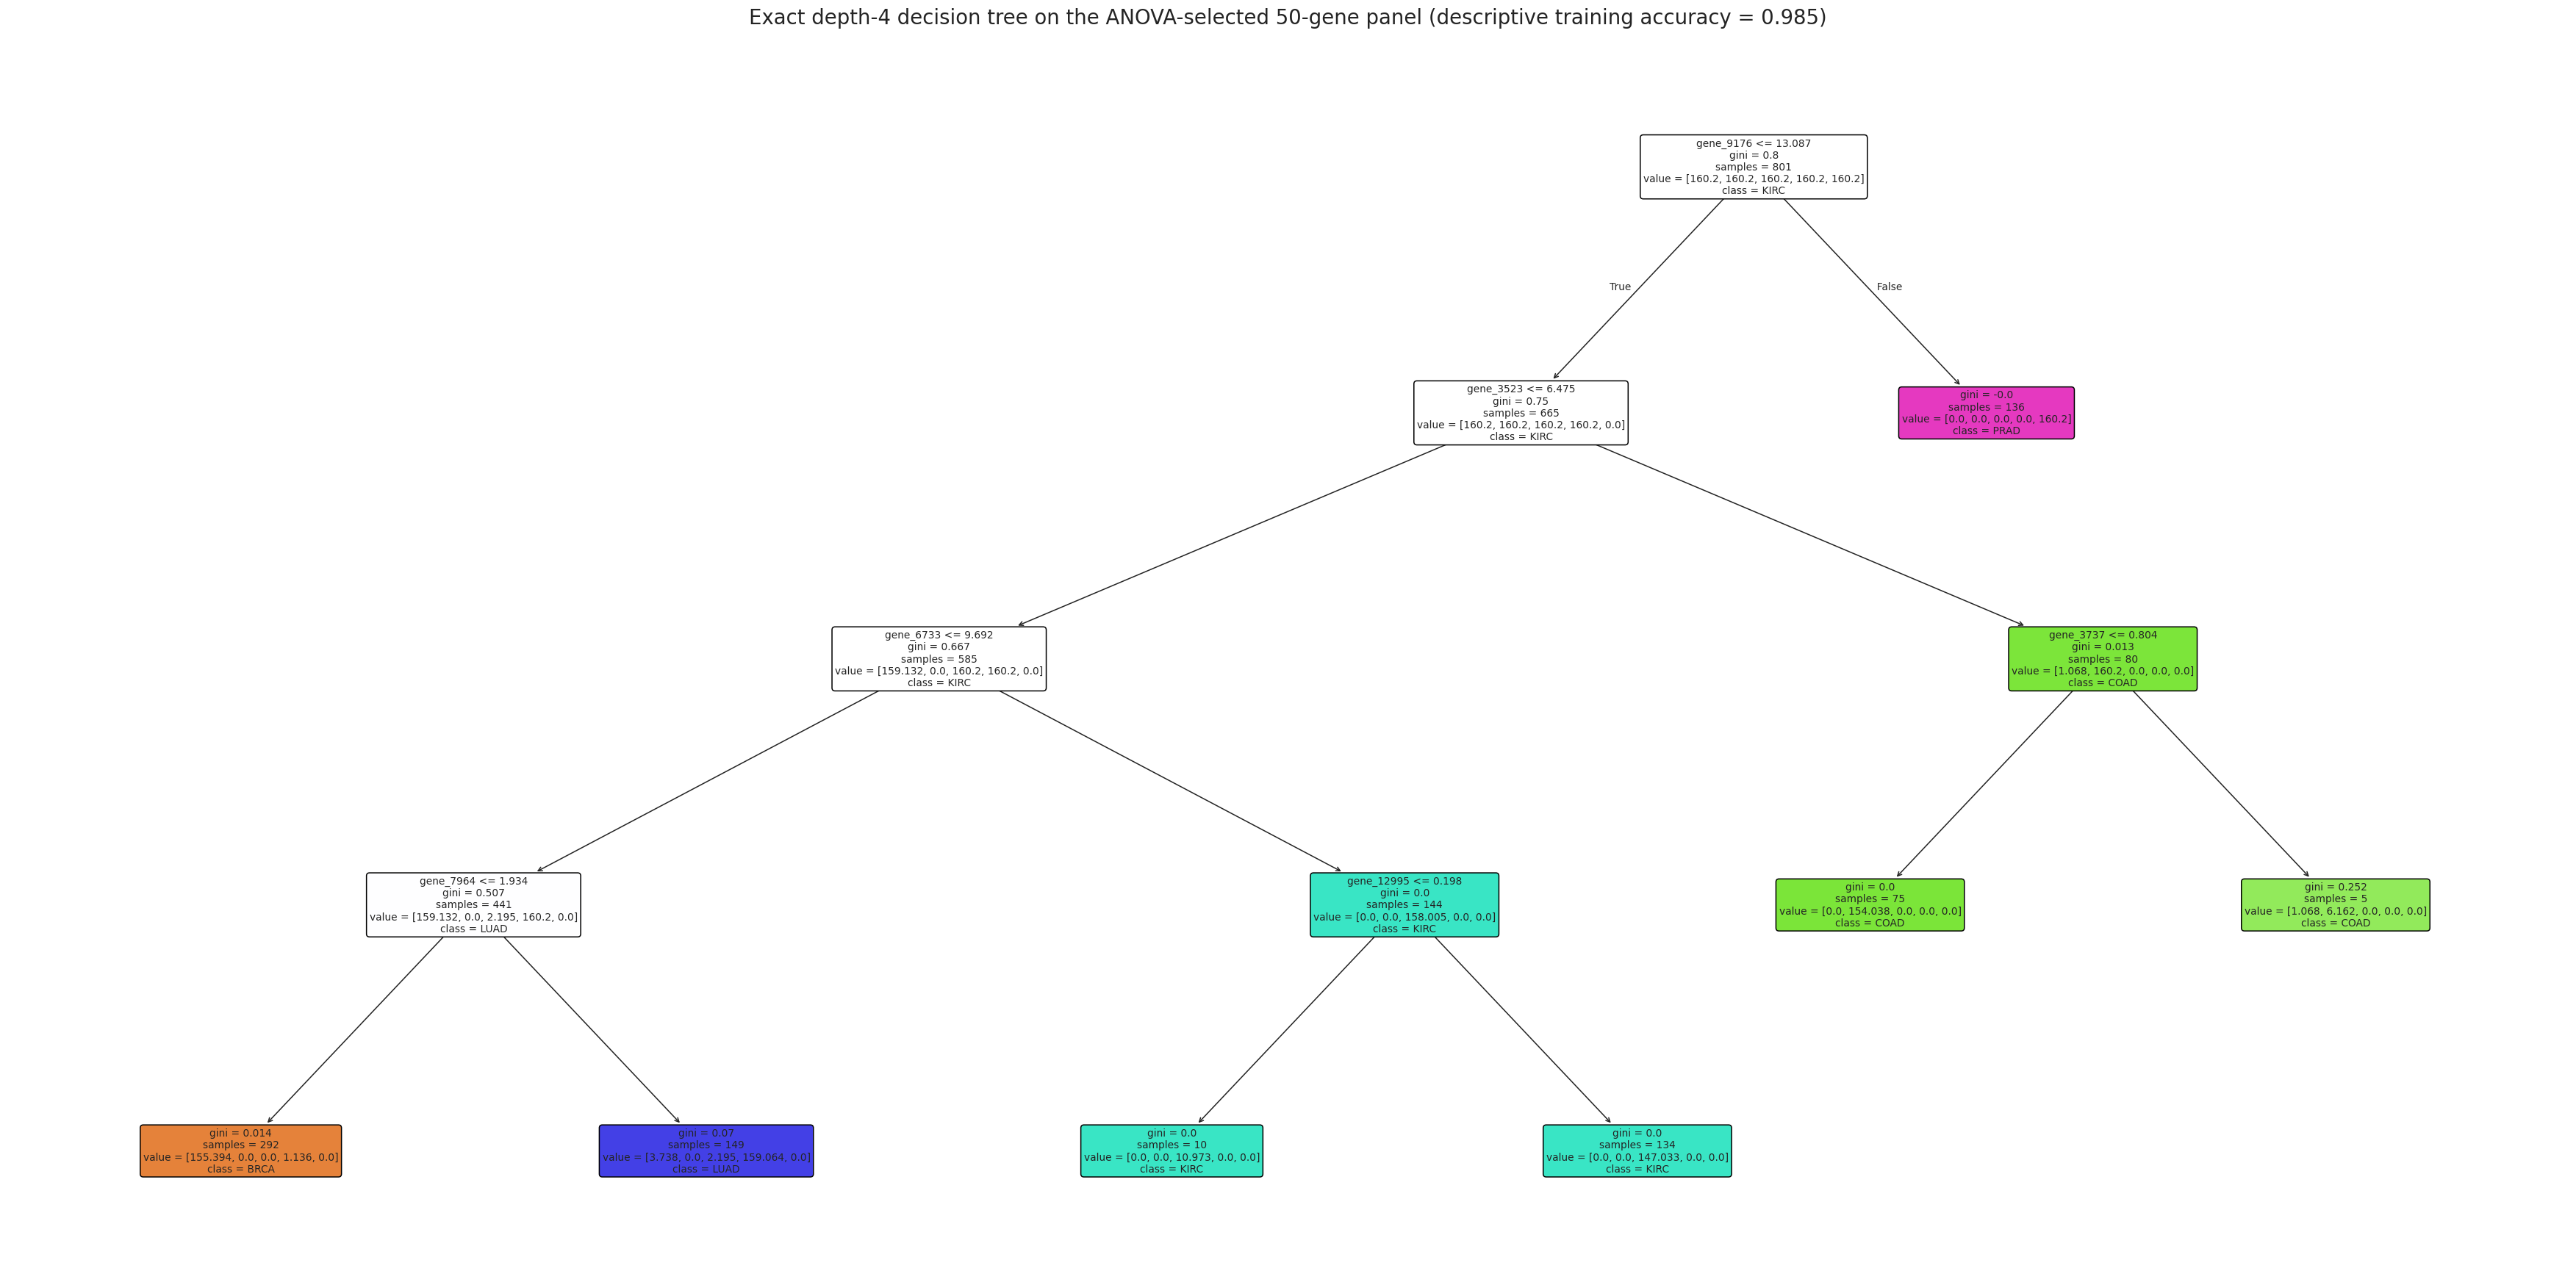


Saved exact tree:
- /Users/richardmohling/Desktop/Uni/M.Sc. Quantive Decision Making in Economics and Management/5. Semester/Data Analytics/Data-Analytics/results_notebook_quick/decision_tree_depth4_exact.png
- /Users/richardmohling/Desktop/Uni/M.Sc. Quantive Decision Making in Economics and Management/5. Semester/Data Analytics/Data-Analytics/results_notebook_quick/decision_tree_depth4_exact.pdf
Explorative Grafiken gespeichert.


### PCA der Tumorproben

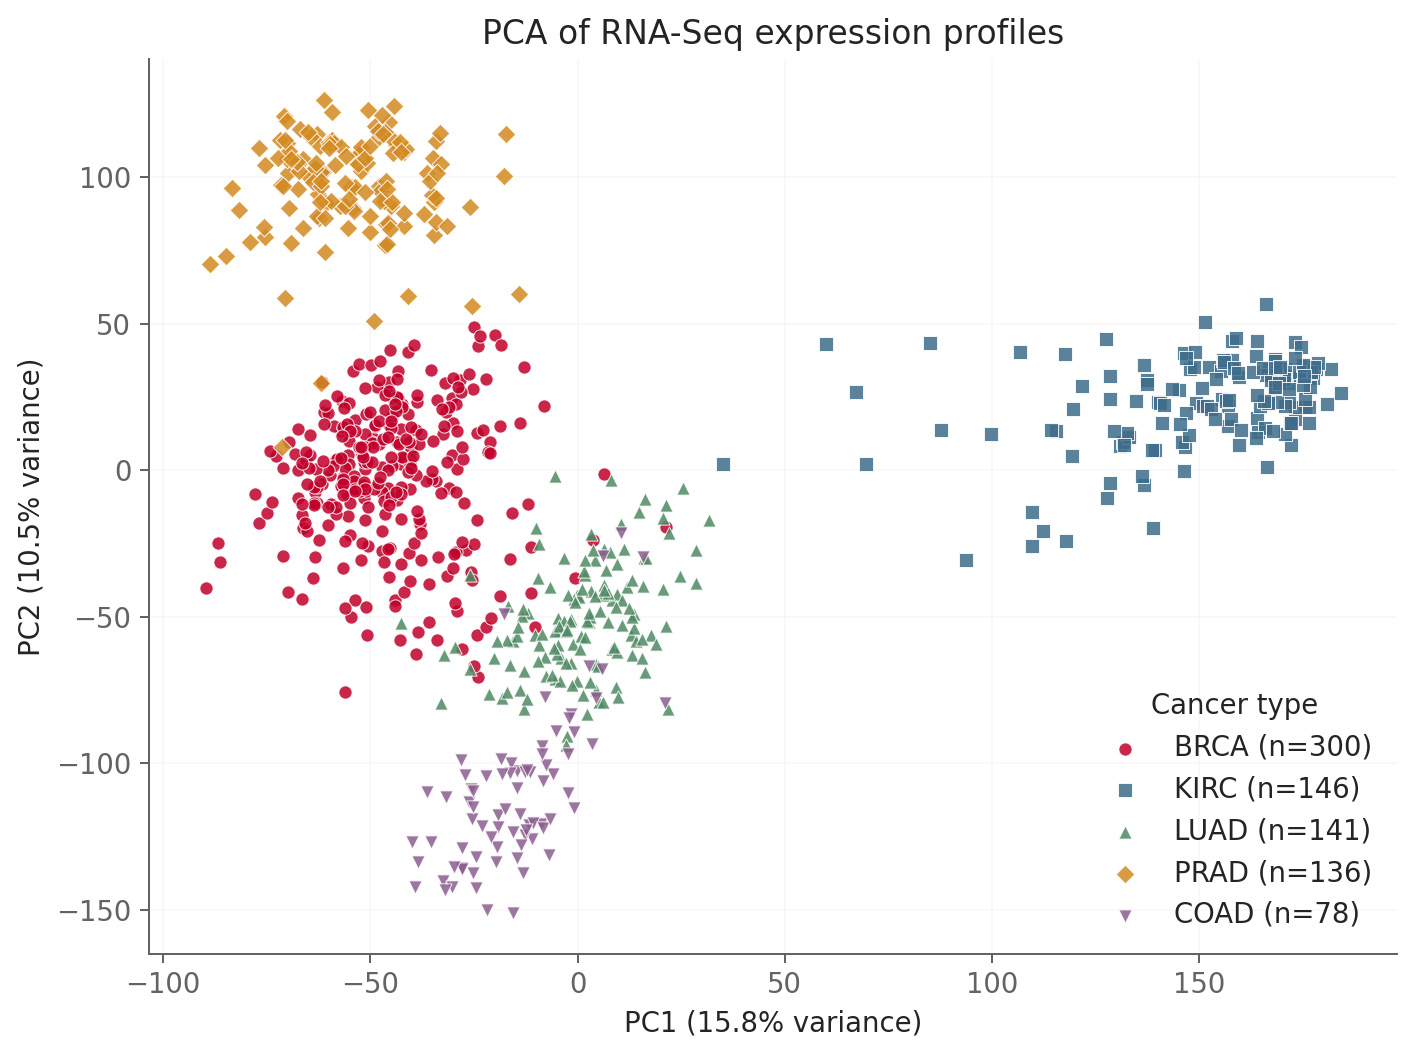

### Erklärte Varianz der Hauptkomponenten

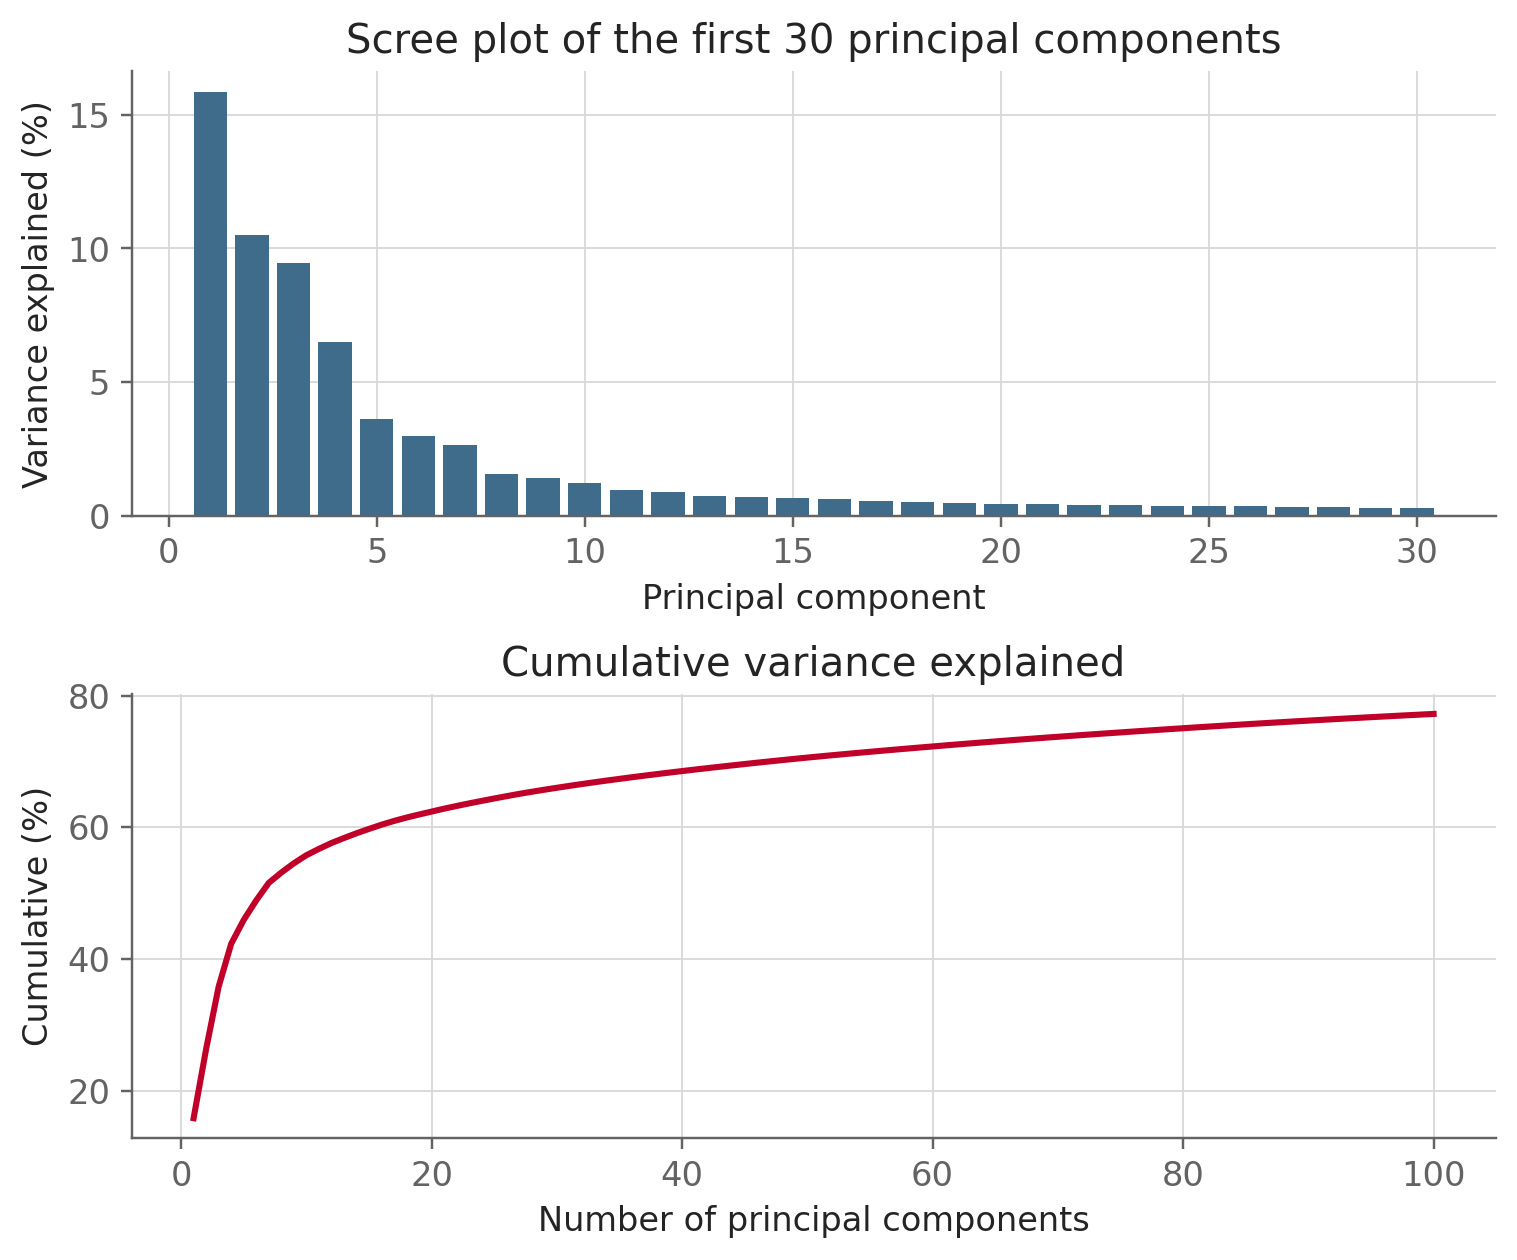

### Verteilung der Genexpressionswerte

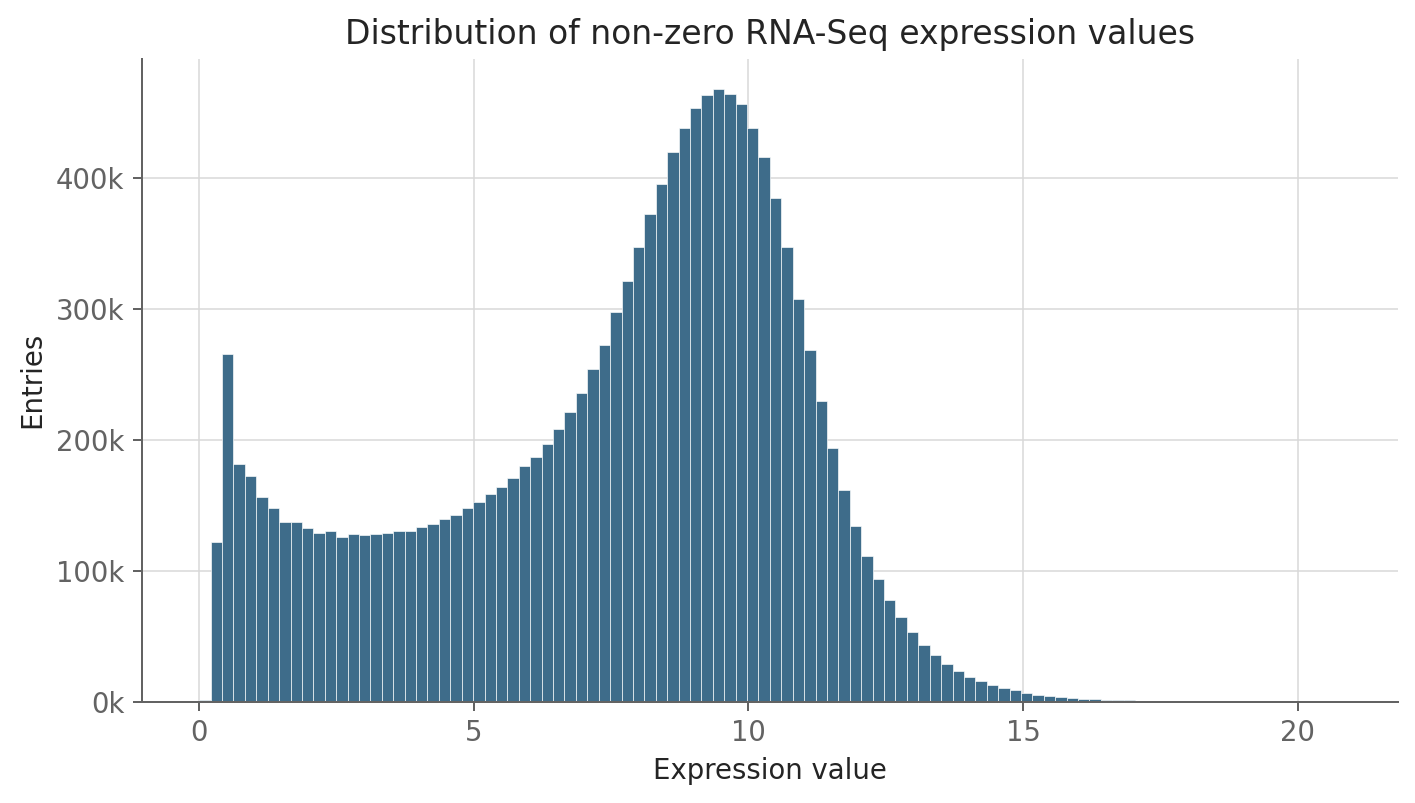

### Einzelner Entscheidungsbaum zur Illustration

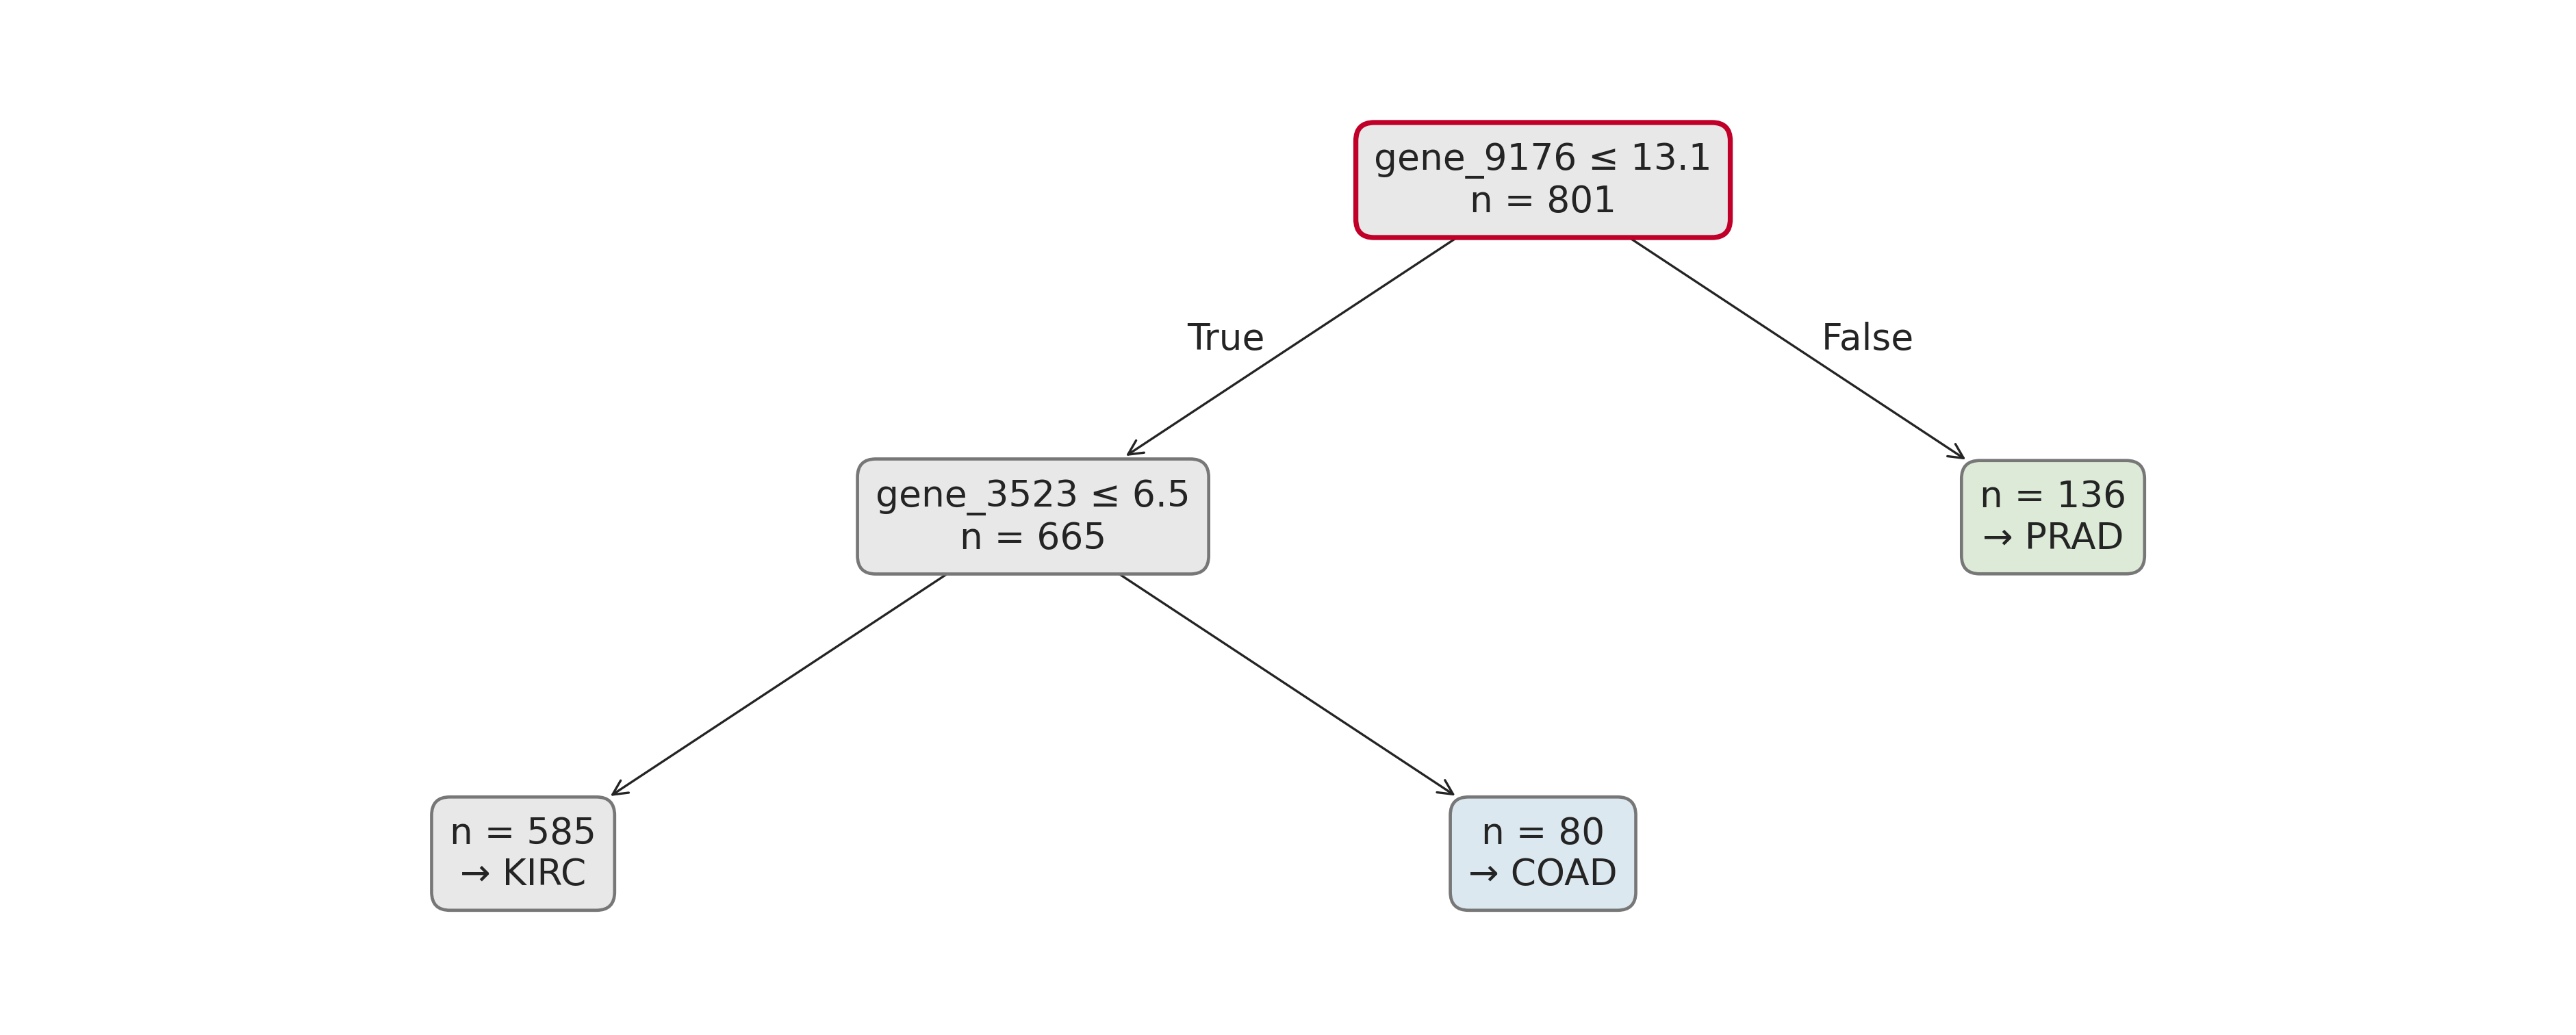

In [76]:
create_pca_plot(X, y, OUTPUT_DIR, cfg.random_state)
create_variance_diagnostics(X, OUTPUT_DIR, cfg.random_state)
create_tree_plot(X, y, OUTPUT_DIR, cfg.random_state)
print("Explorative Grafiken gespeichert.")


display(Markdown("### PCA der Tumorproben"))
show_saved_image(OUTPUT_DIR / "pca_cancer_types.png")
display(Markdown("### Erklärte Varianz der Hauptkomponenten"))
show_saved_image(OUTPUT_DIR / "pca_scree_plot.png")
display(Markdown("### Verteilung der Genexpressionswerte"))
show_saved_image(OUTPUT_DIR / "expression_value_distribution.png")
display(Markdown("### Einzelner Entscheidungsbaum zur Illustration"))
show_saved_image(OUTPUT_DIR / "decision_tree_depth2_presentation.png", width=1100)


### 6.3 All-Gene-Random-Forest als Benchmark


[All-gene random forest] evaluating baseline
All-Gene-Benchmark abgeschlossen.


### All-Gene-Random-Forest: Fold-Ergebnisse

,model,genes,fold,oob_accuracy,accuracy,balanced_accuracy,macro_f1,macro_roc_auc_ovr
0,All-gene random forest,20254,1,0.9963,0.9925,0.9916,0.9938,1.0000
1,All-gene random forest,20243,2,0.9925,1.0000,1.0000,1.0000,1.0000
2,All-gene random forest,20248,3,0.9944,0.9963,0.9957,0.9969,1.0000


### All-Gene-Random-Forest: Confusion Matrix

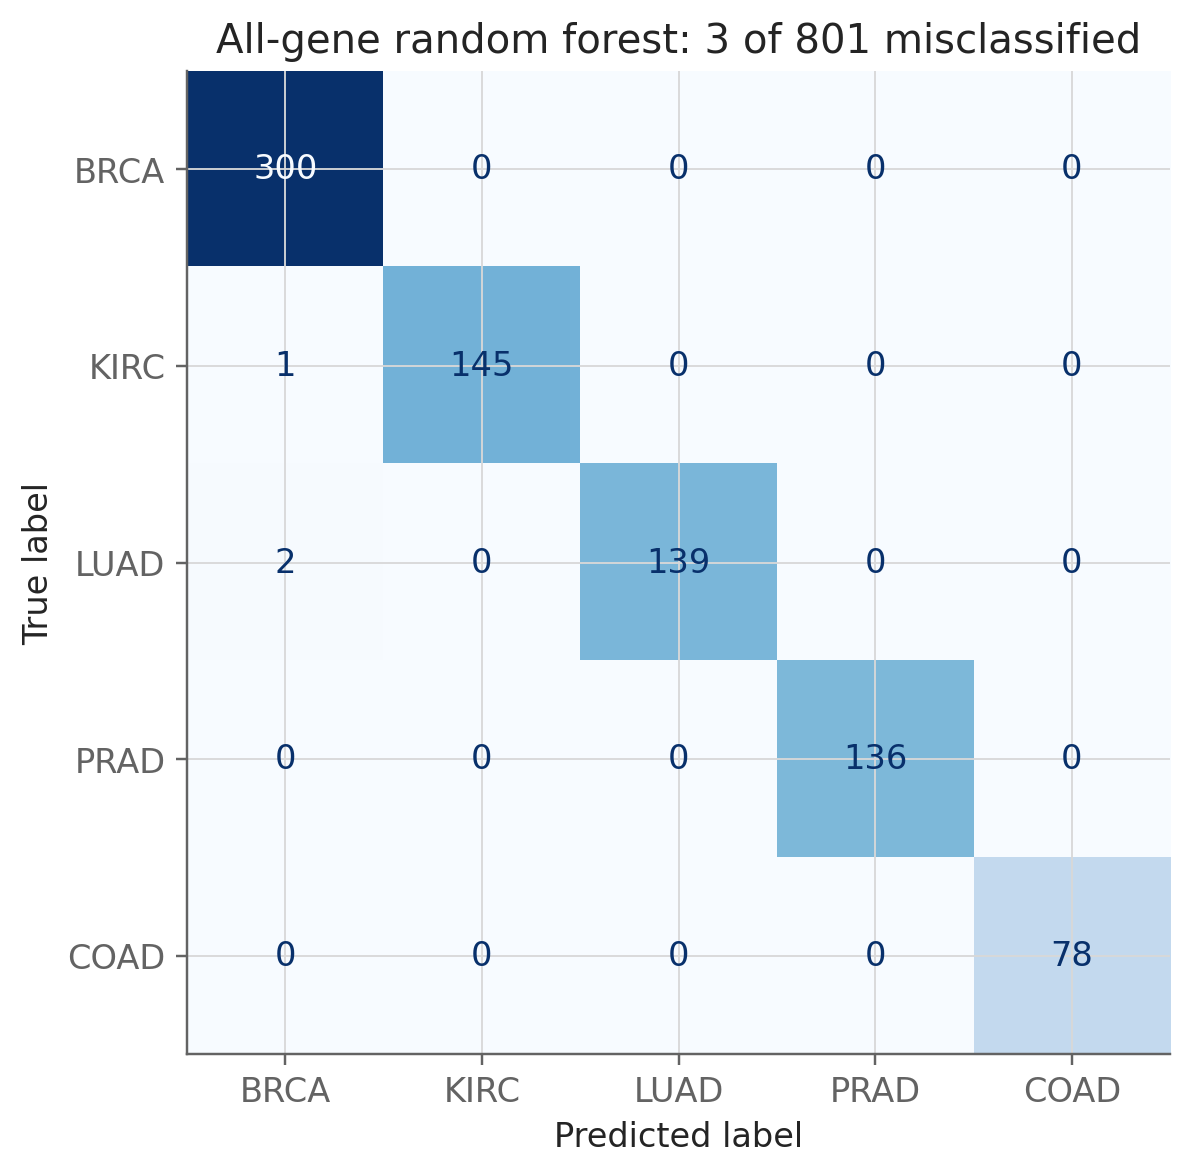

### Wichtigste Gene nach Impurity Importance

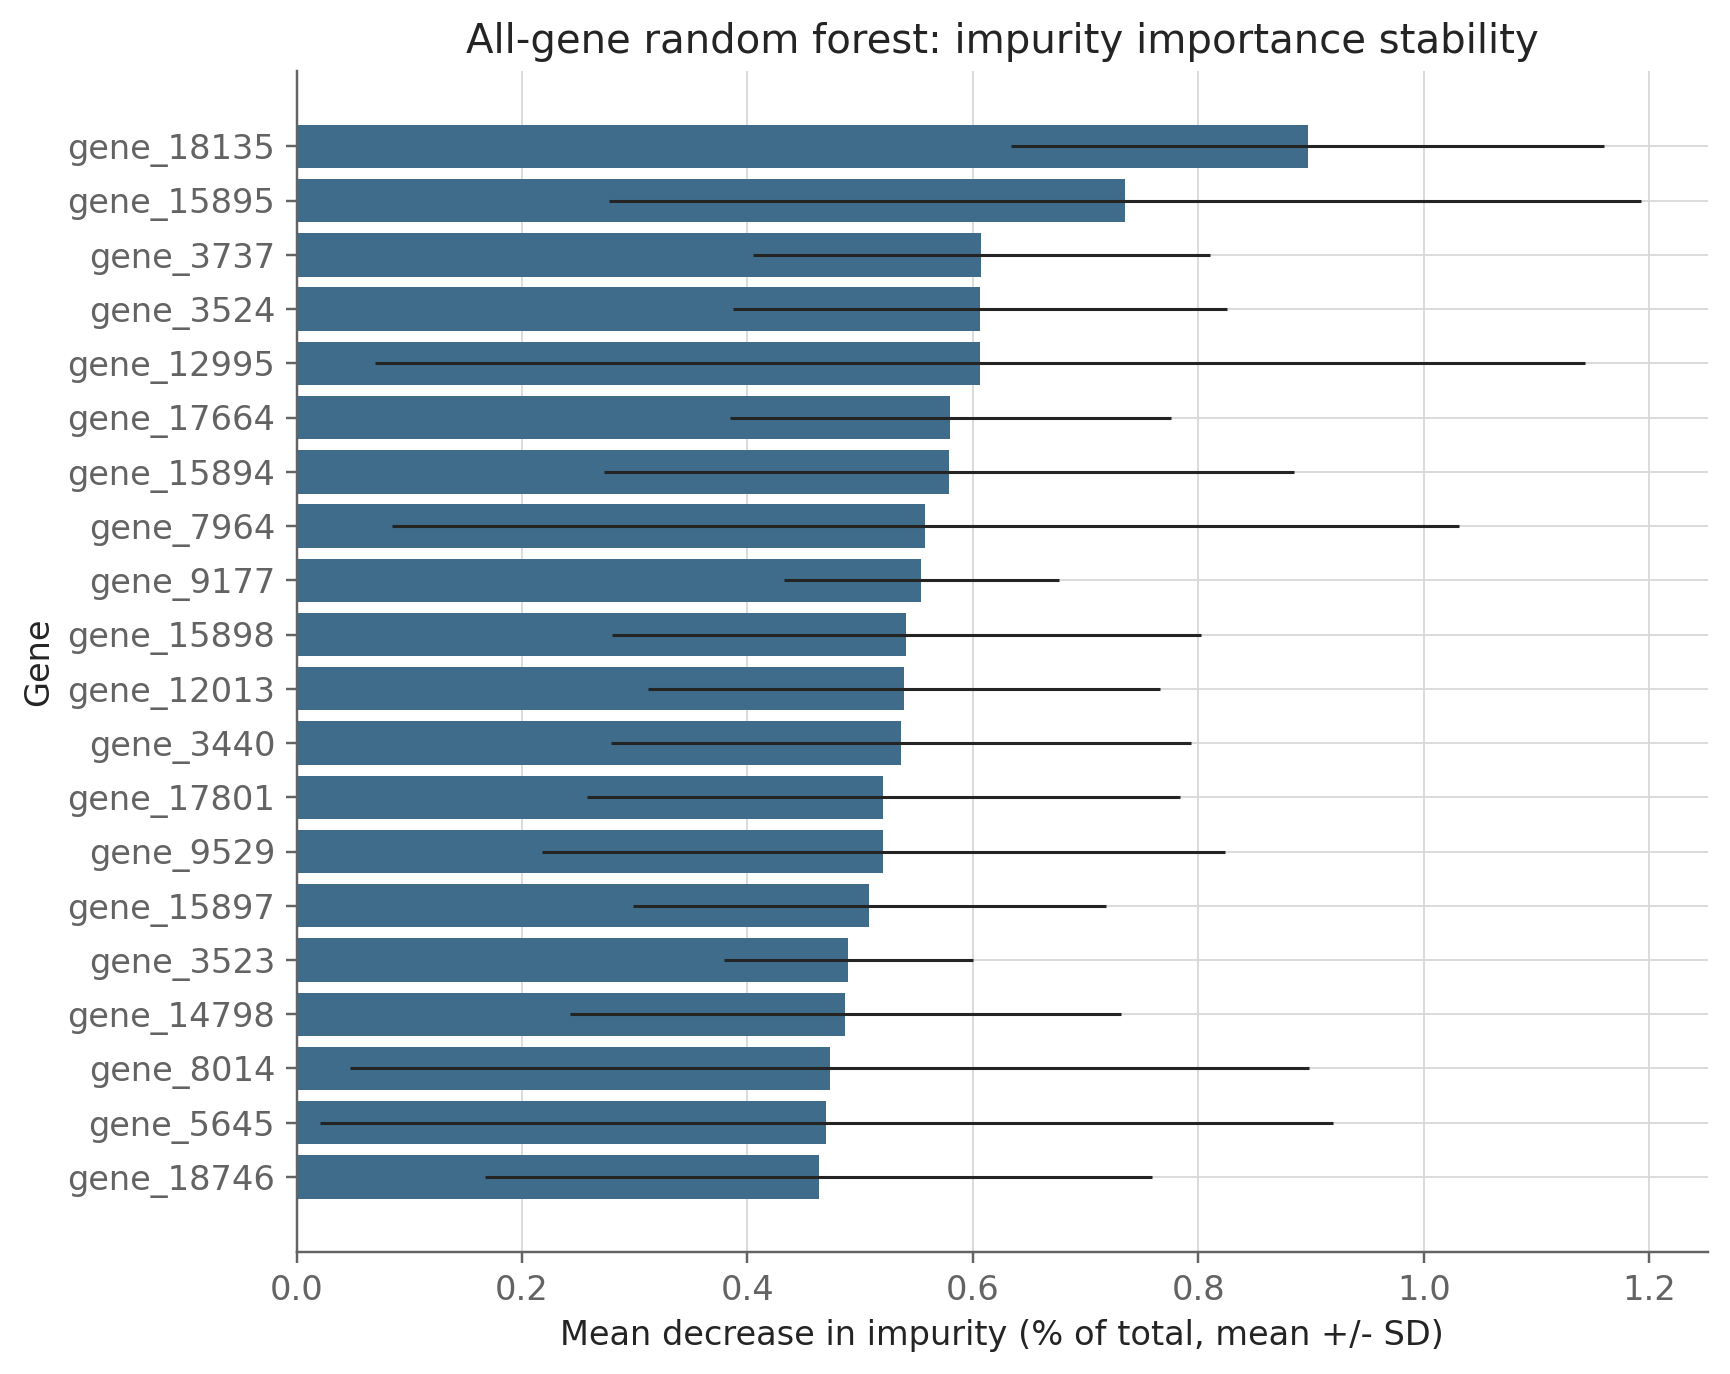

In [77]:
evaluate_all_gene_random_forest(X, y, OUTPUT_DIR, cfg)
print("All-Gene-Benchmark abgeschlossen.")


all_gene_metrics = pd.read_csv(OUTPUT_DIR / "all_gene_rf_fold_metrics.csv")
display(Markdown("### All-Gene-Random-Forest: Fold-Ergebnisse"))
display(all_gene_metrics.style.format(precision=4))
display(Markdown("### All-Gene-Random-Forest: Confusion Matrix"))
show_saved_image(OUTPUT_DIR / "all_gene_rf_confusion_matrix.png", width=650)
display(Markdown("### Wichtigste Gene nach Impurity Importance"))
show_saved_image(OUTPUT_DIR / "all_gene_rf_impurity_importance.png", width=850)


### 6.4 Feature Selection und Modellvergleich


In [ ]:
metrics, selections, importances = evaluate_models(X, y, OUTPUT_DIR, cfg)
metrics.head()


metric_columns = [
    column
    for column in ["accuracy", "balanced_accuracy", "macro_f1", "roc_auc_ovr"]
    if column in metrics.columns
]
gene_count_column = "genes" if "genes" in metrics.columns else "k"
metric_summary = (
    metrics.groupby(["model", gene_count_column])[metric_columns]
    .agg(["mean", "std"])
    .round(4)
)
display(Markdown("### Kreuzvalidierte Modellgüte"))
display(metric_summary)


[Random forest] evaluating k=3
[Random forest] evaluating k=10
[Random forest] evaluating k=50
[Random forest] evaluating k=100
[ANOVA + random forest] evaluating k=3


### 6.5 Tabellen, Abbildungen und Run Notes schreiben


Fertig. Ergebnisse: /Users/richardmohling/Desktop/Uni/M.Sc. Quantive Decision Making in Economics and Management/5. Semester/Data Analytics/Data-Analytics/results_notebook_quick


### Zusammenfassung der Modellgüte

,model,genes,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,macro_f1_mean,macro_f1_std,macro_roc_auc_ovr_mean,macro_roc_auc_ovr_std
0,ANOVA + random forest,3,0.6529,0.0517,0.6339,0.0382,0.6292,0.0427,0.8577,0.0456
1,ANOVA + random forest,10,0.9438,0.0653,0.9369,0.0758,0.9392,0.0736,0.9899,0.0134
2,ANOVA + random forest,50,0.9938,0.0022,0.9918,0.0039,0.9929,0.0045,1.0000,0.0000
3,ANOVA + random forest,100,0.9925,0.0065,0.9904,0.0065,0.9928,0.0048,1.0000,0.0000
4,L1 logistic,3,0.8677,0.0468,0.8509,0.0588,0.8308,0.0707,0.9731,0.0141
5,L1 logistic,10,0.9888,0.0037,0.9872,0.0042,0.9876,0.0036,0.9999,0.0001
6,L1 logistic,50,0.9963,0.0037,0.9958,0.0042,0.9969,0.0031,1.0000,0.0000
7,L1 logistic,100,0.9963,0.0037,0.9957,0.0043,0.9968,0.0032,1.0000,0.0000
8,Random forest,3,0.8377,0.0696,0.8455,0.0526,0.8442,0.0515,0.9562,0.0288
9,Random forest,10,0.9863,0.0078,0.9841,0.0086,0.9853,0.0055,0.9990,0.0015


### Vorhersagegüte in Abhängigkeit von der Genanzahl

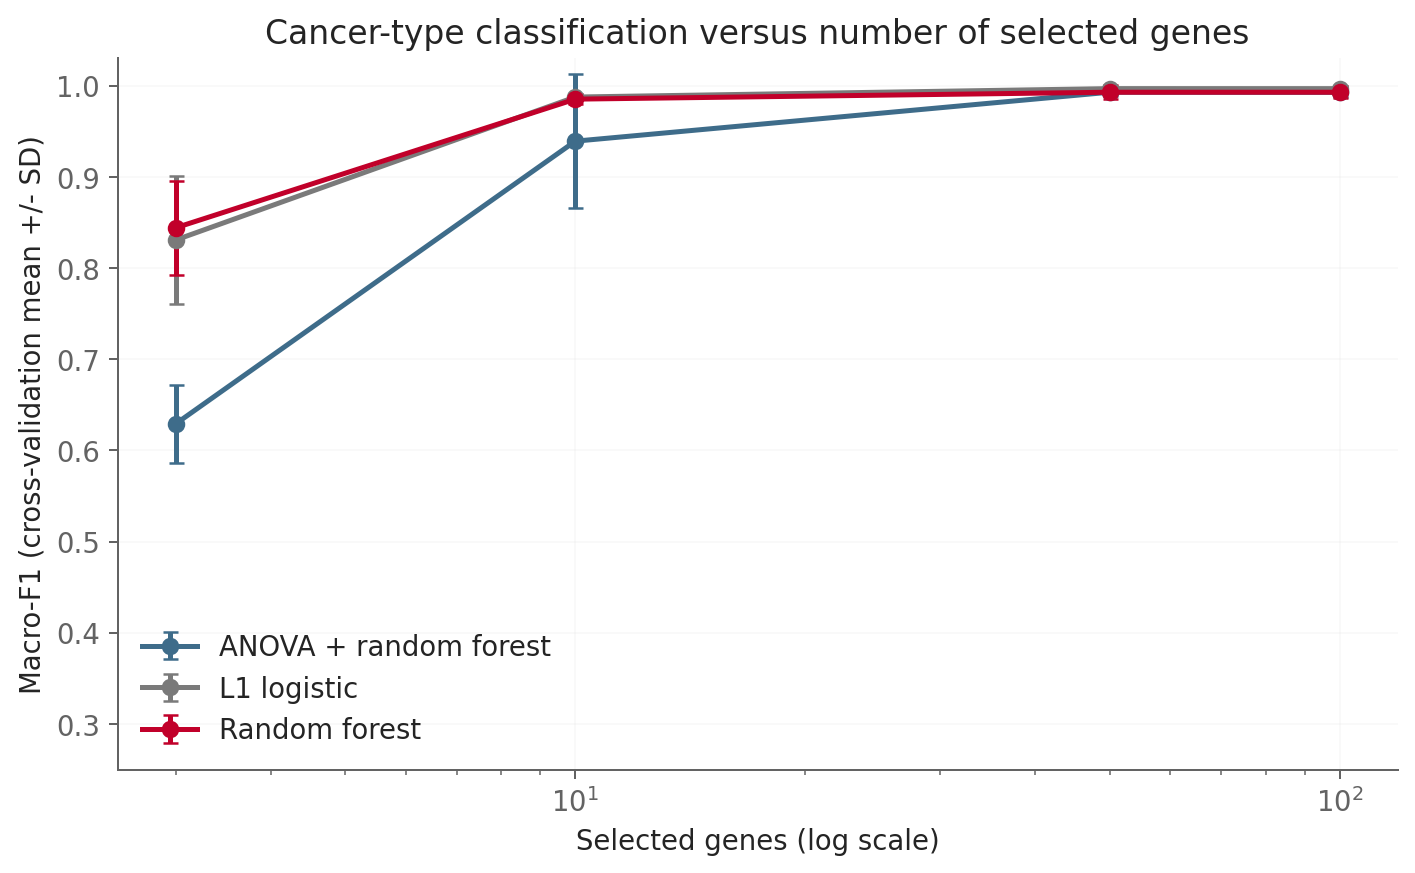

### Held-out Permutation Importance

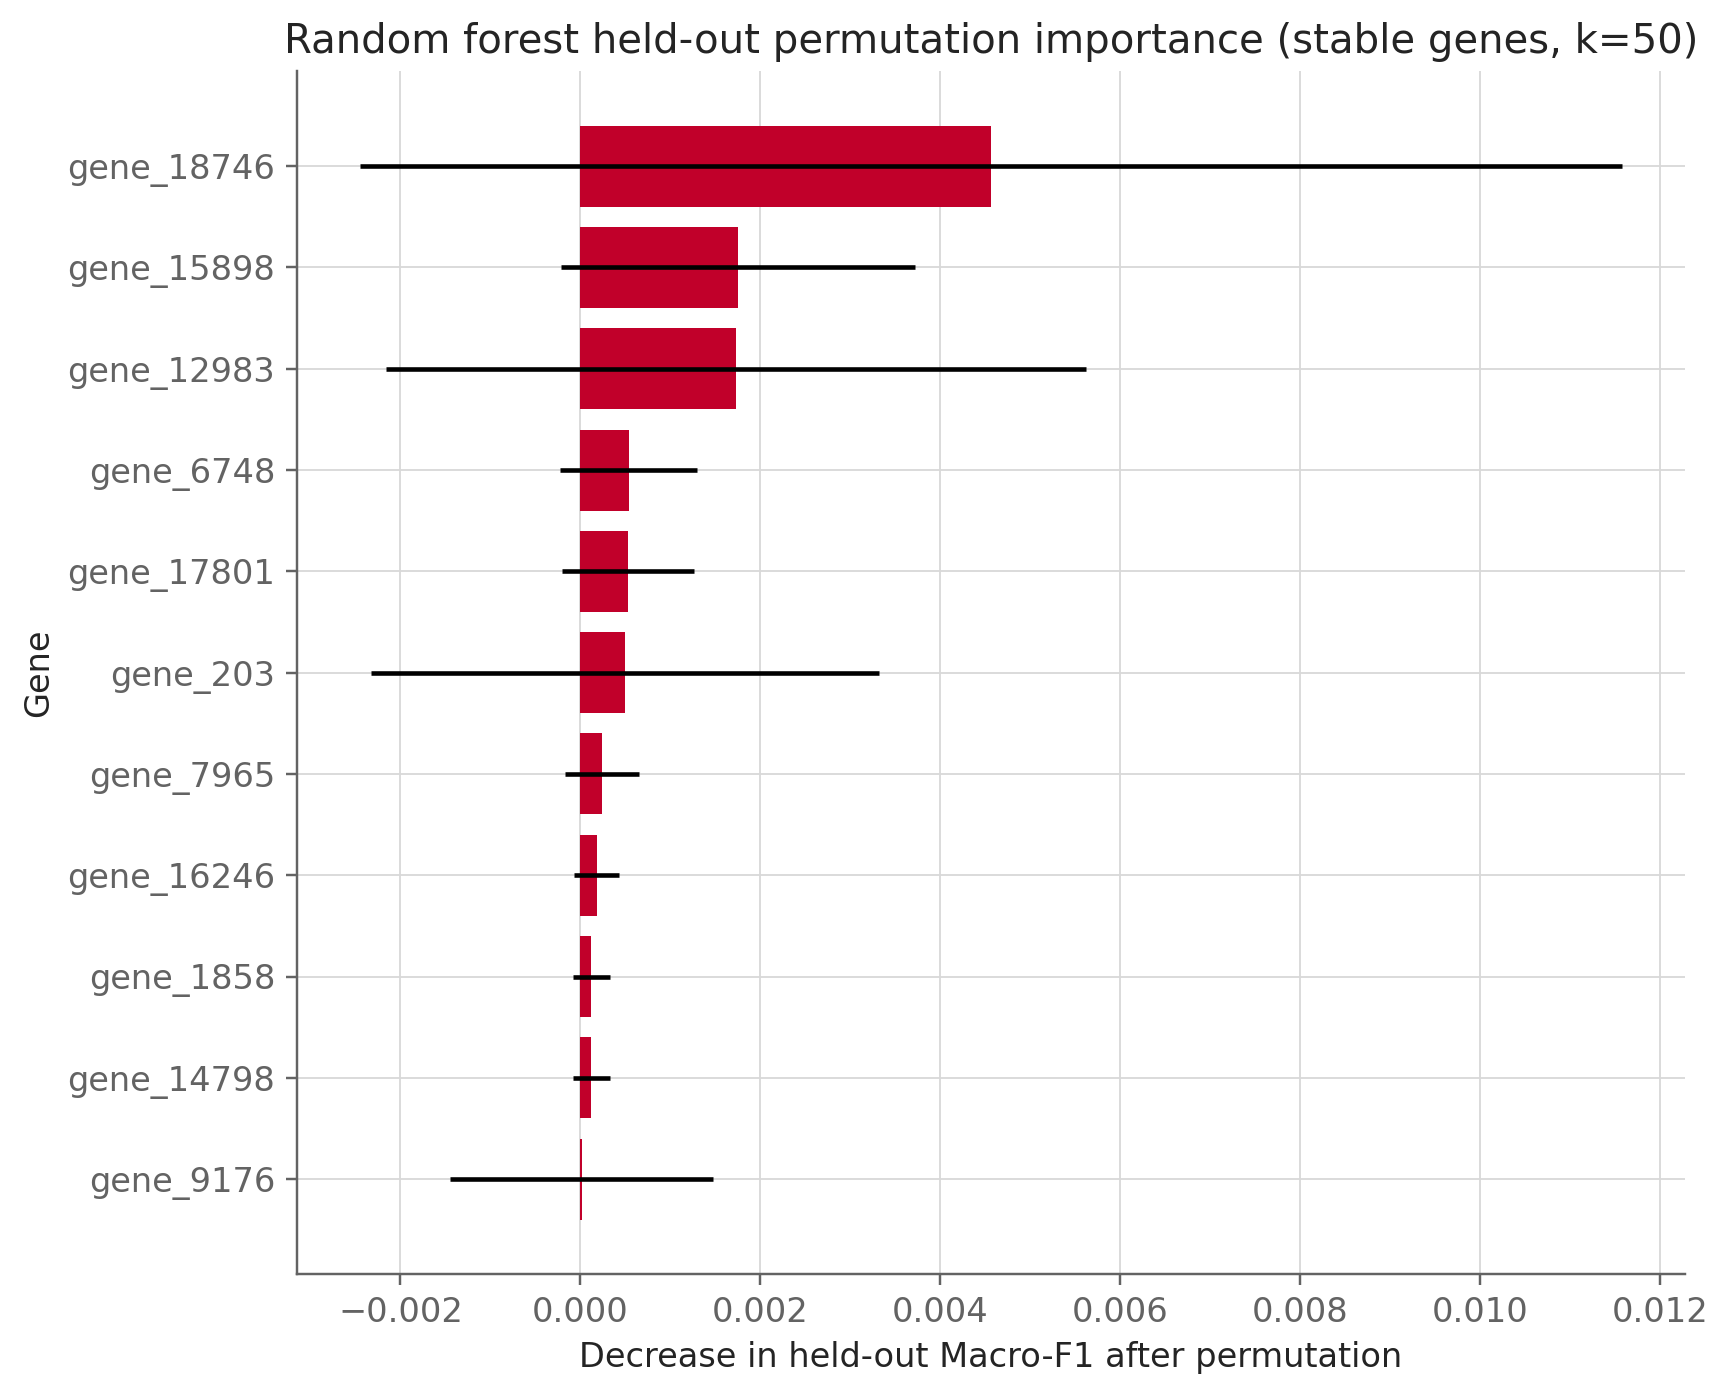

### Sensitive Permutation Importance auf Basis des Log-Loss

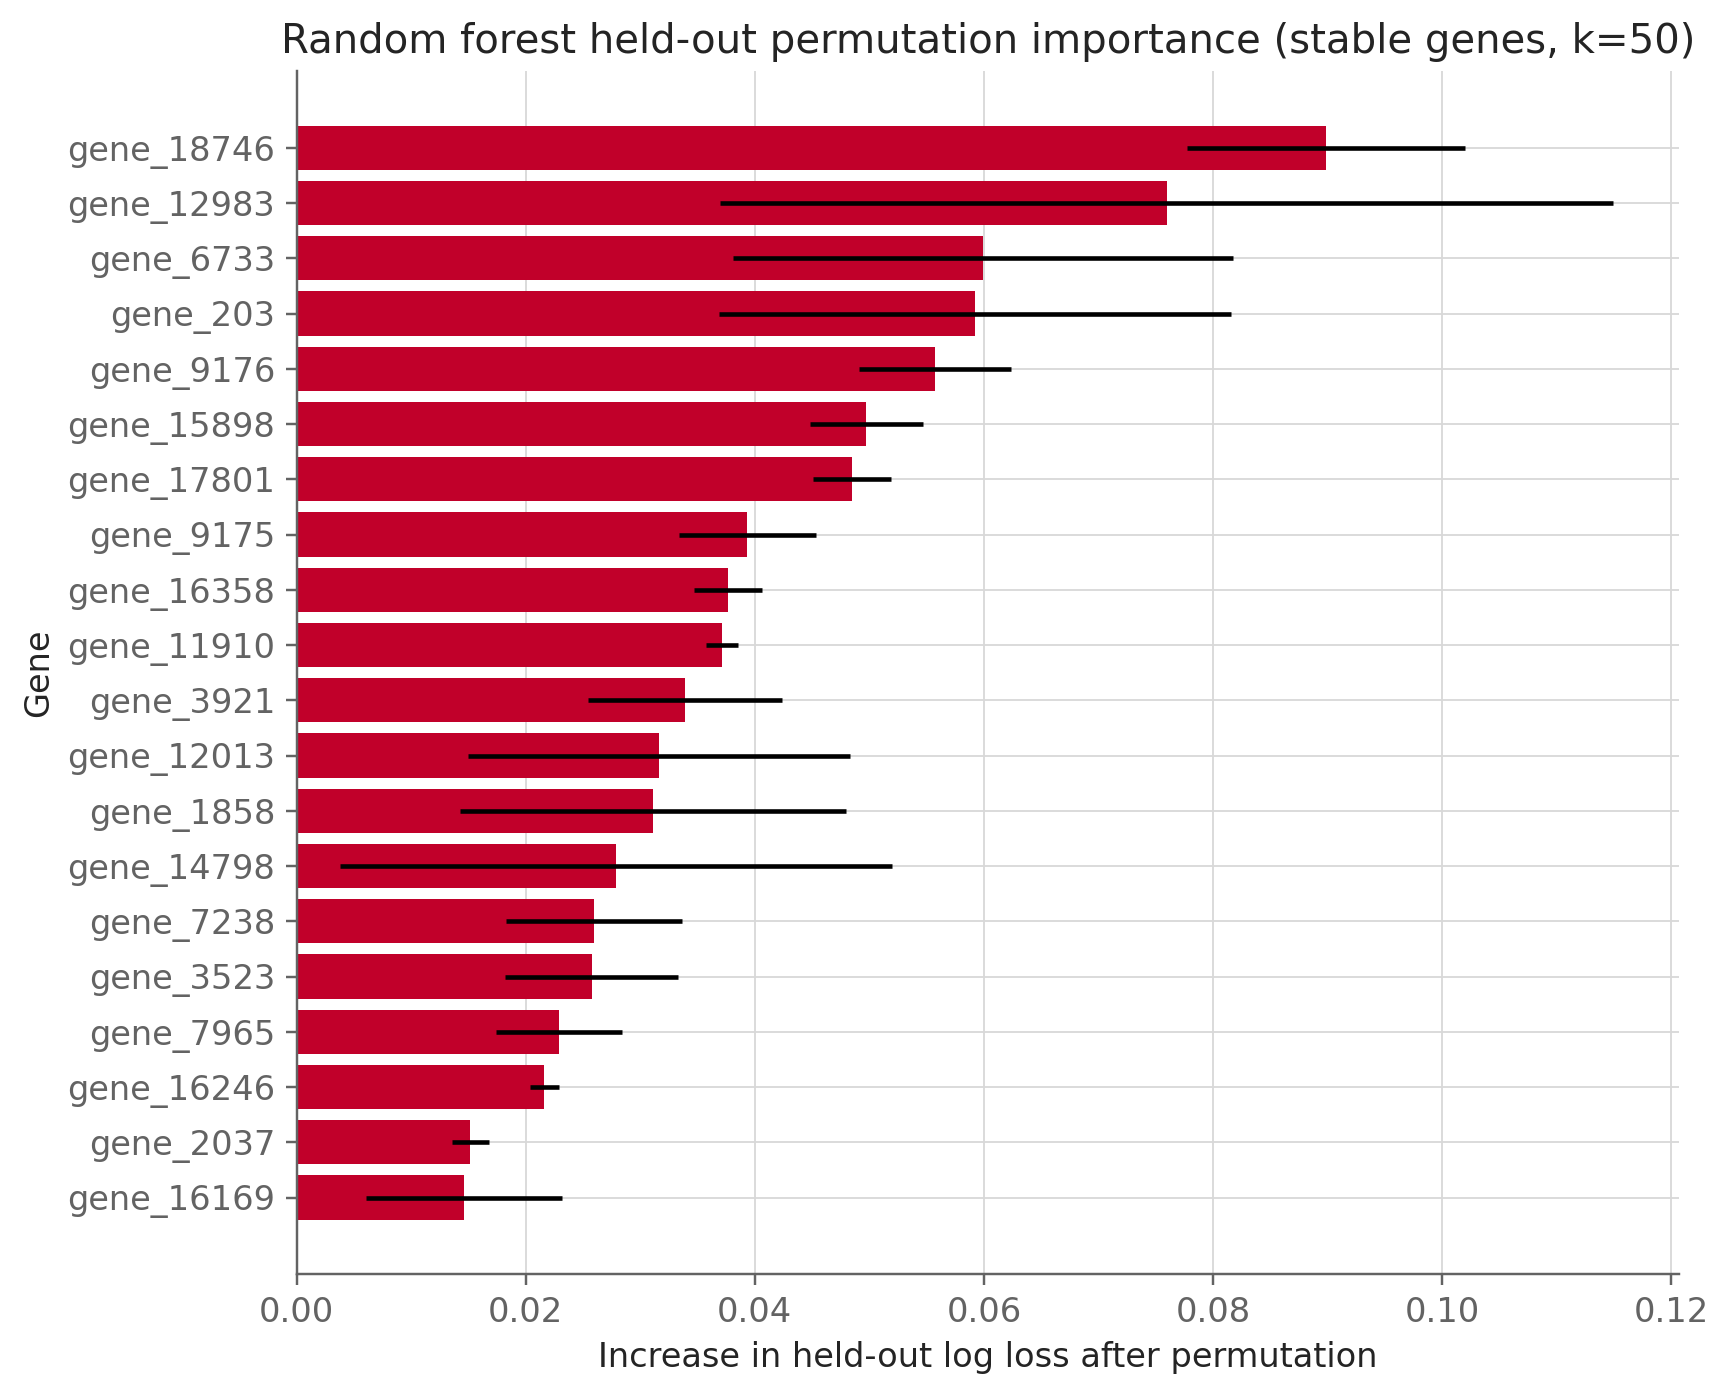

### Out-of-fold Confusion Matrices bei 50 Genen

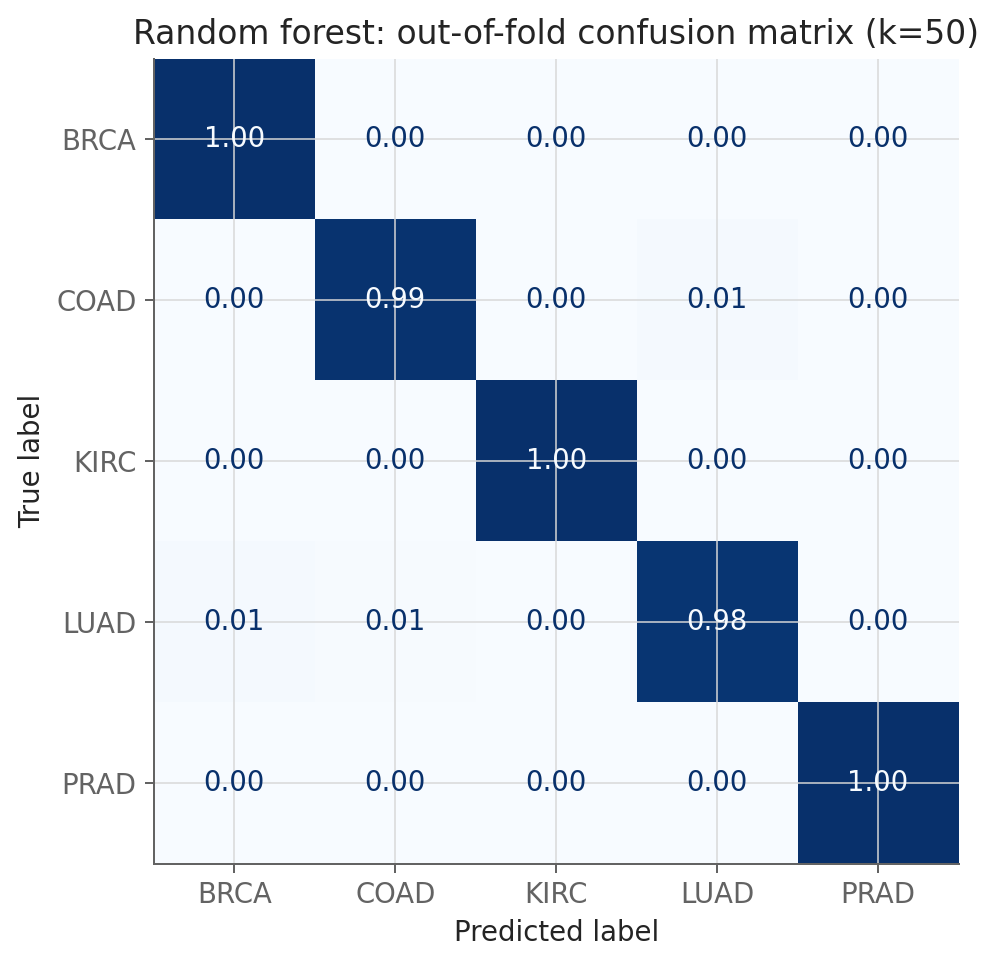

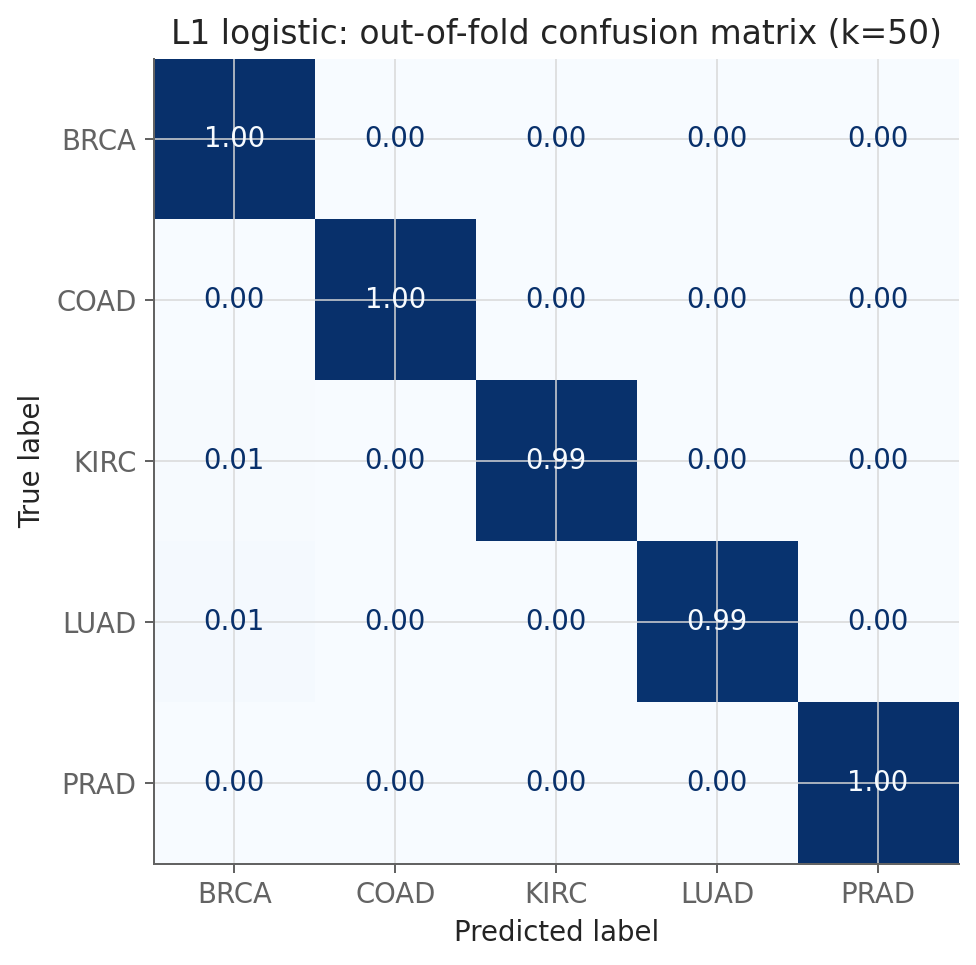

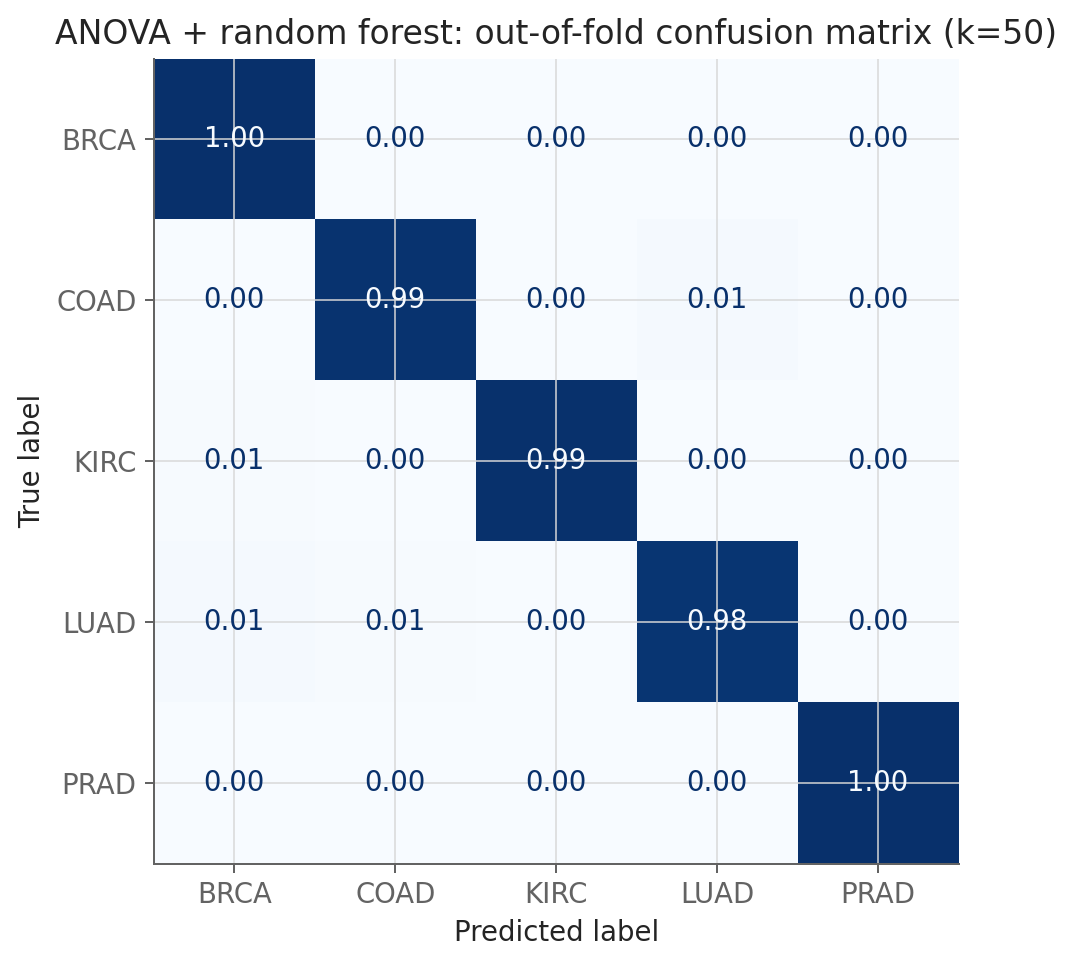

### Stabile Überschneidung aller drei Selektoren

gene,stable_random_forest,stable_anova_forest,stable_l1_logistic,selected_by_all_three
gene_10098,False,False,True,False
gene_10460,False,False,True,False
gene_11566,False,True,False,False
gene_11903,False,True,True,False
gene_11910,True,False,False,False
gene_12013,True,False,True,False
gene_12078,False,True,False,False
gene_12079,True,False,False,False
gene_12808,False,True,True,False
gene_12847,False,True,False,False


In [ ]:
summarize_and_plot_results(
    metrics, selections, importances, OUTPUT_DIR, cfg
)
write_run_notes(OUTPUT_DIR, cfg)
print(f"Fertig. Ergebnisse: {OUTPUT_DIR.resolve()}")


display(Markdown("### Zusammenfassung der Modellgüte"))
display(pd.read_csv(OUTPUT_DIR / "cv_summary.csv").style.format(precision=4))

display(Markdown("### Vorhersagegüte in Abhängigkeit von der Genanzahl"))
show_saved_image(OUTPUT_DIR / "performance_vs_gene_count.png", width=1000)

display(Markdown("### Held-out Permutation Importance"))
show_saved_image(OUTPUT_DIR / "rf_top_permutation_importance.png", width=850)

display(Markdown("### Sensitive Permutation Importance auf Basis des Log-Loss"))
show_saved_image(
    OUTPUT_DIR / "rf_top_permutation_importance_log_loss.png", width=850
)

display(Markdown("### Out-of-fold Confusion Matrices bei 50 Genen"))
for image_name in [
    "confusion_matrix_random_forest_k50.png",
    "confusion_matrix_l1_logistic_k50.png",
    "confusion_matrix_anova_+_random_forest_k50.png",
]:
    show_saved_image(OUTPUT_DIR / image_name, width=600)

stable_path = OUTPUT_DIR / "stable_gene_overlap_all_selectors_k50.csv"
if stable_path.exists():
    display(Markdown("### Stabile Überschneidung aller drei Selektoren"))
    display(pd.read_csv(stable_path).style.hide(axis="index"))


## Interpretation

- Der Modellvergleich basiert auf Macro-F1, damit jede Krebsart gleich gewichtet wird.
- Die Kurve über verschiedene Genanzahlen ist eine interne Modellanalyse und kein
  unabhängiger externer Test.
- Anonymisierte Gen-IDs erlauben keine biologische oder kausale Interpretation.
- Ein potenzielles Genpanel müsste auf einer unabhängigen Kohorte extern validiert
  und biologisch zugeordnet werden.
